In [ ]:
!pip install numpy pandas scipy scikit-learn matplotlib seaborn tensorflow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import resample

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf

print("Setup completed successfully!")

Setup completed successfully!


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'sign_language_data', 'australian+sign+language+signs+high+quality (2).zip', 'sample_data']


In [ ]:
for root, dirs, files in os.walk("/content/sign_language_data"):
    print("\nFolder:", root)
    print("Files:", files[:10])


Folder: /content/sign_language_data
Files: ['tctodd.tar.bz2', 'tctodd.tar.gz', 'auslan.data.html', 'auslan.html']


In [ ]:
import tarfile
import os

dataset_file = "/content/sign_language_data/tctodd.tar.bz2"
dataset_folder = "/content/sign_language_data/auslan"

with tarfile.open(dataset_file, "r:bz2") as tar:
    tar.extractall(dataset_folder)

print("Actual dataset extracted!")
print(os.listdir(dataset_folder))

ReadError: not a bzip2 file

In [ ]:
import tarfile
import os

dataset_file = "/content/sign_language_data/tctodd.tar.gz"
dataset_folder = "/content/sign_language_data/auslan"

with tarfile.open(dataset_file, "r:gz") as tar:
    tar.extractall(dataset_folder)

print("Actual dataset extracted successfully!")
print(os.listdir(dataset_folder))

ReadError: not a gzip file

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=115)

print("Dataset downloaded successfully!")

DatasetNotFoundError: "Australian Sign Language Signs (High Quality)" dataset (id=115) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true

In [ ]:
!pip install pyreadr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.4/829.4 kB 12.5 MB/s eta 0:00:00


In [ ]:
# Download the mfds R package containing the AustralianLanguage dataset
!wget -q https://cran.r-project.org/src/contrib/mfds_0.1.0.tar.gz -O /content/mfds.tar.gz

# Extract it
!tar -xzf /content/mfds.tar.gz -C /content/

print("Package downloaded and extracted!")


gzip: stdin: unexpected end of file
tar: Child returned status 1
tar: Error is not recoverable: exiting now
Package downloaded and extracted!


In [ ]:
import os

# Check that the dataset file exists
dataset_path = "/content/mfds/data/AustralianLanguage.rda"

print("Dataset exists:", os.path.exists(dataset_path))
print("Dataset path:", dataset_path)

Dataset exists: False
Dataset path: /content/mfds/data/AustralianLanguage.rda


In [ ]:
!find /content/mfds -type f | head -50

find: ‘/content/mfds’: No such file or directory


In [ ]:
!ls -lh /content/mfds.tar.gz

-rw-r--r-- 1 root root 0 Oct  6 18:34 /content/mfds.tar.gz


In [ ]:
!git clone https://github.com/Halmaris/mfds.git /content/mfds

Cloning into '/content/mfds'...
remote: Enumerating objects: 52, done.
remote: Total 52 (delta 0), reused 0 (delta 0), pack-reused 52 (from 1)
Receiving objects: 100% (52/52), 39.36 MiB | 38.75 MiB/s, done.
Resolving deltas: 100% (14/14), done.


In [ ]:
!find /content/mfds -type f | head -50

/content/mfds/data/ECG.rda
/content/mfds/data/Libras.rda
/content/mfds/data/CharacterTrajectories.rda
/content/mfds/data/Wafer.rda
/content/mfds/data/datalist
/content/mfds/data/PenDigits.rda
/content/mfds/data/JapaneseVowels.rda
/content/mfds/data/Graz.rda
/content/mfds/data/RobotFailure.rda
/content/mfds/data/ArabicDigits.rda
/content/mfds/data/uWaveGestureLibrary.rda
/content/mfds/data/AustralianLanguage.rda
/content/mfds/README.md
/content/mfds/DESCRIPTION
/content/mfds/NAMESPACE
/content/mfds/.git/config
/content/mfds/.git/packed-refs
/content/mfds/.git/info/exclude
/content/mfds/.git/description
/content/mfds/.git/refs/remotes/origin/HEAD
/content/mfds/.git/refs/heads/master
/content/mfds/.git/index
/content/mfds/.git/objects/pack/pack-cb429b2dd10eadab606fdf7efc42ac74e7f25bce.pack
/content/mfds/.git/objects/pack/pack-cb429b2dd10eadab606fdf7efc42ac74e7f25bce.idx
/content/mfds/.git/objects/pack/pack-cb429b2dd10eadab606fdf7efc42ac74e7f25bce.rev
/content/mfds/.git/hooks/pre-receive.s

In [ ]:
import pyreadr

result = pyreadr.read_r('/content/mfds/data/AustralianLanguage.rda')

print("Objects found:")
print(result.keys())

Objects found:
odict_keys([])


In [ ]:
import os

path = "/content/mfds/data/AustralianLanguage.rda"

print("File size:", os.path.getsize(path), "bytes")

print("\nFirst 200 bytes:")
with open(path, "rb") as f:
    print(f.read(200))

File size: 5326204 bytes

First 200 bytes:
b'\xfd7zXZ\x00\x00\x01i"\xde6\x02\x00!\x01\x1c\x00\x00\x00\x10\xcfX\xcc\xe5\xb5T\xef\xfe]\x00)\x11\x07TW"\xe4nR\xca\x9f\x92\xd8\xe2y\xb0\xad\xe0,\xf8\x03eY\x93\xb8\xdalD\xab/\xd0\xcb\x15g(\xcd\x9c\xc8\x10\x90\xf2=\x81UUK\xa3+\xc9\xbff\xce1\xbc\xf7P\xe1+\x95\xf3\xe4\xfe\x12G\xea\xfc73[\xe4\xdf\xee\xd6\x15@\x0e\xc2\xc2[<t\xff\xe3\xae\xc8]\xba\xa7(\xecm\x18\x04\x92\x93k\xb1\xa6\xc8\xd6\xa8\xe3\xc8>z|$\x04\xfd~;\xaa\xa8\xc2\\\xcf\x8c%\xf4\x06\x04\xbd;\xc7qB\xbbI\xb6\x1bQ\x12!\x7f\xab\x87Y\xf1?X\x83\xd6\x8c9\xf3ec\xaf\x7f\xaa\xb9\x9aeo$\xb7\x91\xddJ-\xfe\xf3\x15\xb4\x18uw\'\xcd'


In [ ]:
!Rscript -e "load('/content/mfds/data/AustralianLanguage.rda'); print(ls())"

[1] "AustralianLanguage"


In [ ]:
!Rscript -e "load('/content/mfds/data/AustralianLanguage.rda'); str(AustralianLanguage, max.level=2)"

List of 23
 $ LH_x            : num [1:136, 1:2565] -0.0978 -0.0978 -0.1025 -0.1025 -0.1025 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_y            : num [1:136, 1:2565] -0.128 -0.128 -0.127 -0.127 -0.127 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_z            : num [1:136, 1:2565] -0.0291 -0.0291 -0.0292 -0.0292 -0.0292 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_roll         : num [1:136, 1:2565] 0.538 0.538 0.538 0.538 0.538 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_pitch        : num [1:136, 1:2565] 0.249 0.249 0.246 0.246 0.246 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_yaw          : num [1:136, 1:2565] 0.509 0.509 0.507 0.507 0.507 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_thumb        : num [1:136, 1:2565] 0.239 0.239 0.24 0.24 0.24 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_forefinger   : num [1:136, 1:2565] 0.0398 0.0398 0.0391 0.0391 0.0391 ...
  ..- attr(*, "dimnames")=List of 2
 $ LH_middle_finger: num [1:136, 1:2565] 0 0 0 0 0 0 0 0 0 0 ...
  ..- att

In [ ]:
!Rscript -e "
load('/content/mfds/data/AustralianLanguage.rda');

X <- array(0, dim=c(136, 22, 2565));

for(i in 1:22) {
    X[,i,] <- AustralianLanguage[[i]]
}

# Convert to: samples × (time × features)
X_flat <- matrix(0, nrow=2565, ncol=136*22)

for(i in 1:2565) {
    X_flat[i,] <- as.vector(X[,,i])
}

write.csv(X_flat, '/content/auslan_X.csv', row.names=FALSE)

# Save class labels
write.csv(
    data.frame(class=AustralianLanguage$class),
    '/content/auslan_y.csv',
    row.names=FALSE
)

cat('X shape:', dim(X_flat), '\n')
cat('Number of classes:', length(unique(AustralianLanguage$class)), '\n')
"

SyntaxError: unterminated string literal (detected at line 28) (1427783849.py, line 28)

In [ ]:
%%writefile /content/convert_auslan.R

load("/content/mfds/data/AustralianLanguage.rda")

X <- array(0, dim = c(136, 22, 2565))

for(i in 1:22) {
    X[, i, ] <- AustralianLanguage[[i]]
}

# Convert to samples × (time × features)
X_flat <- matrix(0, nrow = 2565, ncol = 136 * 22)

for(i in 1:2565) {
    X_flat[i, ] <- as.vector(X[, , i])
}

# Save features
write.csv(
    X_flat,
    "/content/auslan_X.csv",
    row.names = FALSE
)

# Save class labels
write.csv(
    data.frame(class = AustralianLanguage$class),
    "/content/auslan_y.csv",
    row.names = FALSE
)

cat("X shape:", dim(X_flat), "\n")
cat("Number of classes:", length(unique(AustralianLanguage$class)), "\n")

Writing /content/convert_auslan.R


In [ ]:
!Rscript /content/convert_auslan.R

X shape: 2565 2992 
Number of classes: 95 


In [ ]:
import pandas as pd
import numpy as np

# Load features and labels
X_flat = pd.read_csv('/content/auslan_X.csv').values
y = pd.read_csv('/content/auslan_y.csv')['class'].values

print("X_flat shape:", X_flat.shape)
print("y shape:", y.shape)

print("\nNumber of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

print("\nMissing values in X:", np.isnan(X_flat).sum())
print("Missing values in y:", pd.isna(y).sum())


X_flat shape: (2565, 2992)
y shape: (2565,)

Number of classes: 95
Classes: ['God' 'I' 'Norway' 'alive' 'all' 'answer' 'boy' 'building' 'buy'
 'change mind' 'cold' 'come' 'computer PC' 'cost' 'crazy' 'danger' 'deaf'
 'different' 'draw' 'drink' 'eat' 'exit' 'flash-light' 'forget' 'girl'
 'give' 'glove' 'go' 'happy' 'head' 'hear' 'hello' 'her' 'hot' 'how'
 'hurry' 'hurt' 'innocent' 'is true' 'joke' 'juice' 'know' 'later' 'lose'
 'love' 'make' 'man' 'maybe' 'mine' 'money' 'more' 'name' 'no'
 'not my problem' 'paper' 'pen' 'please' 'polite' 'question' 'read'
 'ready' 'research' 'responsible' 'right' 'sad' 'same' 'science' 'share'
 'shop' 'soon' 'sorry' 'spend' 'stubborn' 'surprise' 'take' 'temper'
 'thank' 'think' 'tray' 'us' 'voluntary' 'wait notyet' 'what' 'when'
 'where' 'which' 'who' 'why' 'wild' 'will' 'write' 'wrong' 'yes' 'you'
 'zero']

Missing values in X: 0
Missing values in y: 0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"
os.makedirs(project_dir, exist_ok=True)

print("Project folder ready!")

Project folder ready!


In [ ]:
import shutil

shutil.copy(
    "/content/auslan_X.csv",
    project_dir + "/auslan_X.csv"
)

shutil.copy(
    "/content/auslan_y.csv",
    project_dir + "/auslan_y.csv"
)

print("Dataset files backed up to Google Drive!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/auslan_X.csv'

In [ ]:
import os
import subprocess

# Project folder in Google Drive
project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"
os.makedirs(project_dir, exist_ok=True)

# Re-download the dataset package repository
if not os.path.exists("/content/mfds"):
    !git clone -q https://github.com/Halmaris/mfds.git /content/mfds

print("Dataset package ready.")

# Create R conversion script
r_script = """
load("/content/mfds/data/AustralianLanguage.rda")

X <- array(0, dim = c(136, 22, 2565))

for(i in 1:22) {
    X[, i, ] <- AustralianLanguage[[i]]
}

X_flat <- matrix(0, nrow = 2565, ncol = 136 * 22)

for(i in 1:2565) {
    X_flat[i, ] <- as.vector(X[, , i])
}

write.csv(
    X_flat,
    "/content/drive/MyDrive/Sign_Language_Temporal_Classification/auslan_X.csv",
    row.names = FALSE
)

write.csv(
    data.frame(class = AustralianLanguage$class),
    "/content/drive/MyDrive/Sign_Language_Temporal_Classification/auslan_y.csv",
    row.names = FALSE
)

cat("X shape:", dim(X_flat), "\\n")
cat("Number of classes:", length(unique(AustralianLanguage$class)), "\\n")
"""

with open("/content/convert_auslan.R", "w") as f:
    f.write(r_script)

# Run conversion
!Rscript /content/convert_auslan.R

print("\nFiles in Google Drive:")
print(os.listdir(project_dir))

Dataset package ready.
X shape: 2565 2992 
Number of classes: 95 

Files in Google Drive:
['auslan_X.csv', 'auslan_y.csv']


In [ ]:
!wget -O /content/auslan_low_quality.zip \
"https://archive.ics.uci.edu/static/public/114/australian%2Bsign%2Blanguage%2Bsigns.zip"

print("Download complete!")

--2026-10-07 17:21:49--  https://archive.ics.uci.edu/static/public/114/australian%2Bsign%2Blanguage%2Bsigns.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘/content/auslan_low_quality.zip’

/content/auslan_low     [  <=>               ]   2.88M  14.0MB/s    in 0.2s    

2026-10-07 17:21:49 (14.0 MB/s) - ‘/content/auslan_low_quality.zip’ saved [3019818]

Download complete!


In [ ]:
import os

print("File size:", os.path.getsize("/content/auslan_low_quality.zip"), "bytes")

File size: 3019818 bytes


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

print("Files in project folder:")
print(os.listdir(project_dir))

Files in project folder:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Sign_Language_Temporal_Classification'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

print("Files in project folder:")
print(os.listdir(project_dir))

Files in project folder:
['auslan_X.csv', 'auslan_y.csv']


In [ ]:
import os
import zipfile

zip_path = "/content/auslan_low_quality.zip"
extract_path = "/content/auslan_low_quality"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")
print("\nExtracted contents:")

for item in os.listdir(extract_path):
    print(item)


Extraction complete!

Extracted contents:
allsigns.tar.gz
auslan.data.html
auslan.html


In [ ]:
import os
import tarfile

tar_path = "/content/auslan_low_quality/allsigns.tar.gz"
extract_path = "/content/auslan_low_quality/data"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(tar_path, "r:gz") as tar:
    tar.extractall(extract_path)

print("Low-quality data extracted!")

print("\nTop-level contents:")
for item in os.listdir(extract_path):
    print(item)

/tmp/ipykernel_489/605089716.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_path)


Low-quality data extracted!

Top-level contents:
signs


In [ ]:
import os

signs_path = "/content/auslan_low_quality/data/signs"

print("Number of items:", len(os.listdir(signs_path)))

print("\nFirst 30 items:")
for item in os.listdir(signs_path)[:30]:
    print(item)

Number of items: 18

First 30 items:
stephen3
adam1
andrew2
john2
andrew1
waleed4
john4
waleed1
john5
andrew3
stephen2
waleed2
stephen1
john3
john1
adam2
stephen4
waleed3


In [ ]:
import os

signs_path = "/content/auslan_low_quality/data/signs"

# Pick the first signer
signer = sorted(os.listdir(signs_path))[0]
signer_path = os.path.join(signs_path, signer)

print("Signer:", signer)
print("Number of items:", len(os.listdir(signer_path)))

print("\nFirst 30 items:")
for item in os.listdir(signer_path)[:30]:
    print(item)

Signer: adam1
Number of items: 190

First 30 items:
wait(notyet)0.sign
voluntary1.sign
change(mind)1.sign
deaf0.sign
name0.sign
man1.sign
think1.sign
glove1.sign
juice1.sign
man0.sign
ready0.sign
computer(PC)0.sign
read1.sign
paper0.sign
different1.sign
question1.sign
stubborn1.sign
God0.sign
name1.sign
write1.sign
same0.sign
you1.sign
hurry0.sign
surprise0.sign
lose1.sign
surprise1.sign
hear1.sign
different0.sign
drink0.sign
happy1.sign


In [ ]:
import os

signs_path = "/content/auslan_low_quality/data/signs"

# Pick one signer
signer = sorted(os.listdir(signs_path))[0]
signer_path = os.path.join(signs_path, signer)

# Pick the first .sign file
sign_file = sorted(
    [f for f in os.listdir(signer_path) if f.endswith(".sign")]
)[0]

file_path = os.path.join(signer_path, sign_file)

print("Signer:", signer)
print("File:", sign_file)
print("Path:", file_path)

print("\nFirst 10 lines:\n")

with open(file_path, "r", errors="ignore") as f:
    for i, line in enumerate(f):
        print(line.rstrip())
        if i >= 9:
            break

Signer: adam1
File: God0.sign
Path: /content/auslan_low_quality/data/signs/adam1/God0.sign

First 10 lines:

0.000000, 0.000000, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000, 0.250000, 0.250000, 0x0, 0x0, 0x0, 0x3F
0.000000, 0.000000, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.250000, 0.250000, 0.250000, 0x0, 0x0, 0x0, 0x3F
0.000000, 0.000000, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000, 0.250000, 0.250000, 0xFF, 0x0, 0x0, 0x3F
-0.015625, 0.000000, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000, 0.250000, 0.250000, 0xFF, 0x0, 0x0, 0x3F
-0.023438, 0.000000, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000, 0.250000, 0.250000, 0xFF, 0x0, 0x0, 0x3F
-0.046875, 0.015625, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000, 0.250000, 0.250000, 0xFF, 0x0, 0x0, 0x3F
-0.046875, 0.031250, -0.007812, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000

In [ ]:
import os

signs_path = "/content/auslan_low_quality/data/signs"

signer = sorted(os.listdir(signs_path))[0]
signer_path = os.path.join(signs_path, signer)

sign_file = sorted(
    [f for f in os.listdir(signer_path) if f.endswith(".sign")]
)[0]

file_path = os.path.join(signer_path, sign_file)

# Read all lines
with open(file_path, "r", errors="ignore") as f:
    lines = [line.strip() for line in f if line.strip()]

print("Signer:", signer)
print("File:", sign_file)
print("Number of time steps:", len(lines))

# Inspect number of comma-separated values
first_values = [x.strip() for x in lines[0].split(",")]

print("Values in first time step:", len(first_values))
print("\nValues:")
for i, value in enumerate(first_values):
    print(i, "->", value)

Signer: adam1
File: God0.sign
Number of time steps: 85
Values in first time step: 15

Values:
0 -> 0.000000
1 -> 0.000000
2 -> 0.000000
3 -> 0.083333
4 -> -1.000000
5 -> -1.000000
6 -> 0.250000
7 -> 0.000000
8 -> 0.000000
9 -> 0.250000
10 -> 0.250000
11 -> 0x0
12 -> 0x0
13 -> 0x0
14 -> 0x3F


In [ ]:
import os
from collections import Counter

signs_path = "/content/auslan_low_quality/data/signs"

total_files = 0
signer_counts = {}
class_counts = Counter()
sequence_lengths = []

for signer in sorted(os.listdir(signs_path)):
    signer_path = os.path.join(signs_path, signer)

    if not os.path.isdir(signer_path):
        continue

    files = [
        f for f in os.listdir(signer_path)
        if f.endswith(".sign")
    ]

    signer_counts[signer] = len(files)
    total_files += len(files)

    for filename in files:
        # Class name = filename without final instance number
        name = filename[:-5]  # remove .sign

        # Remove trailing instance number
        while name and name[-1].isdigit():
            name = name[:-1]

        class_counts[name] += 1

        # Count time steps
        filepath = os.path.join(signer_path, filename)

        with open(filepath, "r", errors="ignore") as f:
            length = sum(1 for line in f if line.strip())

        sequence_lengths.append(length)

print("Number of signers:", len(signer_counts))
print("Signers:", signer_counts)

print("\nTotal recordings:", total_files)
print("Number of classes:", len(class_counts))

print("\nMinimum samples/class:", min(class_counts.values()))
print("Maximum samples/class:", max(class_counts.values()))

print("\nSequence length:")
print("Minimum:", min(sequence_lengths))
print("Maximum:", max(sequence_lengths))
print("Average:", sum(sequence_lengths) / len(sequence_lengths))

Number of signers: 18
Signers: {'adam1': 190, 'adam2': 570, 'andrew1': 95, 'andrew2': 475, 'andrew3': 190, 'john1': 95, 'john2': 475, 'john3': 475, 'john4': 475, 'john5': 190, 'stephen1': 98, 'stephen2': 490, 'stephen3': 489, 'stephen4': 490, 'waleed1': 490, 'waleed2': 490, 'waleed3': 490, 'waleed4': 490}

Total recordings: 6757
Number of classes: 98

Minimum samples/class: 36
Maximum samples/class: 70

Sequence length:
Minimum: 0
Maximum: 4494
Average: 58.428444575995265


In [ ]:
print("All detected classes and their sample counts:\n")

for label, count in sorted(class_counts.items()):
    print(f"{label:30s} {count}")

All detected classes and their sample counts:

God                            70
I                              70
Norway                         70
alive                          70
all                            70
answer                         70
boy                            70
building                       70
buy                            70
cal-full-forward               36
cal-full-right                 36
cal-full-up                    36
change(mind)                   70
cold                           70
come                           70
computer(PC)                   70
cost                           70
crazy                          70
danger                         70
deaf                           70
different                      70
draw                           70
drink                          70
eat                            70
exit                           70
flash-light                    70
forget                         70
girl                           70
g

In [ ]:
print("Classes with counts different from 70:\n")

for label, count in sorted(class_counts.items()):
    if count != 70:
        print(f"{label:30s} {count}")

Classes with counts different from 70:

cal-full-forward               36
cal-full-right                 36
cal-full-up                    36
happy                          69


In [ ]:
import os

print("Happy recordings by session:\n")

for signer in sorted(os.listdir(signs_path)):
    signer_path = os.path.join(signs_path, signer)

    if not os.path.isdir(signer_path):
        continue

    happy_files = [
        f for f in os.listdir(signer_path)
        if f.startswith("happy") and f.endswith(".sign")
    ]

    if happy_files:
        print(f"{signer:10s} -> {len(happy_files)} : {sorted(happy_files)}")

Happy recordings by session:

adam1      -> 2 : ['happy0.sign', 'happy1.sign']
adam2      -> 6 : ['happy0.sign', 'happy1.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign', 'happy5.sign']
andrew1    -> 1 : ['happy0.sign']
andrew2    -> 5 : ['happy0.sign', 'happy1.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign']
andrew3    -> 2 : ['happy0.sign', 'happy1.sign']
john1      -> 1 : ['happy0.sign']
john2      -> 5 : ['happy0.sign', 'happy1.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign']
john3      -> 5 : ['happy0.sign', 'happy1.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign']
john4      -> 5 : ['happy0.sign', 'happy1.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign']
john5      -> 2 : ['happy0.sign', 'happy1.sign']
stephen1   -> 1 : ['happy0.sign']
stephen2   -> 5 : ['happy0.sign', 'happy1.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign']
stephen3   -> 4 : ['happy0.sign', 'happy2.sign', 'happy3.sign', 'happy4.sign']
stephen4   -> 5 : ['happy0.sign', 'happy1.sign', 'happy2.sign',

In [ ]:
import shutil
import os

drive_project = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

# Save the downloaded raw Low-Quality dataset
source_file = "/content/auslan_low_quality.zip"
destination_file = os.path.join(
    drive_project,
    "auslan_low_quality_raw.zip"
)

shutil.copy2(source_file, destination_file)

print("Raw Low-Quality dataset saved successfully!")
print("Saved to:", destination_file)
print("File size:", round(os.path.getsize(destination_file) / (1024 * 1024), 2), "MB")

Raw Low-Quality dataset saved successfully!
Saved to: /content/drive/MyDrive/Sign_Language_Temporal_Classification/auslan_low_quality_raw.zip
File size: 2.88 MB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

print("Project folder exists:", os.path.isdir(project_dir))

if os.path.isdir(project_dir):
    print("\nFiles available:")
    for filename in sorted(os.listdir(project_dir)):
        print("-", filename)
else:
    print("Project folder not found. Check the shared folder shortcut in Drive.")

Project folder exists: True

Files available:
- auslan_X.csv
- auslan_low_quality_raw.zip
- auslan_y.csv


In [ ]:
import os
import numpy as np
import pandas as pd

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

# Load High-Quality dataset
X_flat = pd.read_csv(
    os.path.join(project_dir, "auslan_X.csv")
).values

y = pd.read_csv(
    os.path.join(project_dir, "auslan_y.csv")
)["class"].values

# Verify dataset
print("High-Quality Dataset Verification")
print("-" * 35)
print("Feature shape:", X_flat.shape)
print("Label shape:", y.shape)
print("Number of classes:", len(np.unique(y)))
print("Missing feature values:", np.isnan(X_flat).sum())
print("Missing labels:", pd.isna(y).sum())
print("Number of unique recordings:", len(y))

High-Quality Dataset Verification
-----------------------------------
Feature shape: (2565, 2992)
Label shape: (2565,)
Number of classes: 95
Missing feature values: 0
Missing labels: 0
Number of unique recordings: 2565


In [ ]:
import os
import zipfile
import tarfile

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

zip_path = os.path.join(project_dir, "auslan_low_quality_raw.zip")
extract_path = "/content/auslan_low_quality"
data_path = os.path.join(extract_path, "data")

# Extract the outer ZIP
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Outer ZIP extracted.")

# Extract the inner TAR.GZ
inner_archive = os.path.join(extract_path, "allsigns.tar.gz")
os.makedirs(data_path, exist_ok=True)

with tarfile.open(inner_archive, "r:gz") as tar:
    tar.extractall(data_path)

print("Inner archive extracted.")
print("Top-level contents:", os.listdir(data_path))
print("Signs directory exists:",
      os.path.isdir(os.path.join(data_path, "signs")))

Outer ZIP extracted.


/tmp/ipykernel_1111/3976891823.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(data_path)


Inner archive extracted.
Top-level contents: ['signs']
Signs directory exists: True


In [ ]:
import os

signs_path = os.path.join(data_path, "signs")

# Find one session folder
sessions = sorted(
    name for name in os.listdir(signs_path)
    if os.path.isdir(os.path.join(signs_path, name))
)

print("Number of session folders:", len(sessions))
print("Example session folders:", sessions[:5])

# Find one recording
session_path = os.path.join(signs_path, sessions[0])
recordings = sorted(
    name for name in os.listdir(session_path)
    if name.endswith(".sign")
)

print("\nExample session:", sessions[0])
print("Number of recordings in this session:", len(recordings))

sample_file = os.path.join(session_path, recordings[0])

with open(sample_file, "r", errors="ignore") as f:
    lines = [line.strip() for line in f if line.strip()]

print("\nSample recording:", recordings[0])
print("Number of time steps:", len(lines))
print("Values in first time step:", len(lines[0].split(",")))
print("First time step:", lines[0])

Number of session folders: 18
Example session folders: ['adam1', 'adam2', 'andrew1', 'andrew2', 'andrew3']

Example session: adam1
Number of recordings in this session: 190

Sample recording: God0.sign
Number of time steps: 85
Values in first time step: 15
First time step: 0.000000, 0.000000, 0.000000, 0.083333, -1.000000, -1.000000, 0.250000, 0.000000, 0.000000, 0.250000, 0.250000, 0x0, 0x0, 0x0, 0x3F


In [ ]:
import os

for filename in ["auslan.html", "auslan.data.html"]:
    filepath = os.path.join(extract_path, filename)

    if os.path.exists(filepath):
        print(f"\n--- {filename} ---")

        with open(filepath, "r", errors="ignore") as f:
            content = f.read()

        # Print the section around the sensor variable descriptions
        for keyword in ["x", "thumb", "keycode", "receiver"]:
            position = content.lower().find(keyword)

            if position != -1:
                print(f"\nContext for '{keyword}':")
                print(content[max(0, position - 200):position + 500])


--- auslan.html ---

Context for 'x':
ITLE>

<BODY BGCOLOR="#FFFFFF">

<H1> Recordings of a subset of Australian Sign Language signs. </H1>


<H2> Abstract</H2>
<p>This data consists of sample of Auslan (Australian Sign Language) signs. Examples of 95 signs were collected from five signers with a total of 6650 sign samples.



<p><B> Information files:</B>

<UL>
  <LI> <a href="auslan.data.html"> description of the data </a>
</UL>

<p><B> Data files:</B>

<UL>
  <LI> <a href="allsigns.tar.gz"> allsigns.tar.gz</a> (3.0M; 59.0M uncompressed)
</UL>


<p>
<HR>
<ADDRESS>
<A href="http://kdd.ics.uci.edu/">The UCI KDD Archive</A><br>
<a href="http://www.ics.uci.edu/">
Information and Computer Science</a><BR>
<a href="http://www.uci.edu

--- auslan.data.html ---

Context for 'x':
---------------
<!  Abstract
<!----------------------------------------------------------------------->
<H2>Abstract</H2>
<p>
This data consists of sample of Auslan (Australian Sign Language) signs. Examples of 95 si

In [ ]:
import os

doc_path = os.path.join(extract_path, "auslan.data.html")

with open(doc_path, "r", errors="ignore") as f:
    doc_text = f.read()

# Search for the section describing the data fields
for keyword in ["Data Format", "Data format", "Variables", "x:", "Position information"]:
    pos = doc_text.lower().find(keyword.lower())

    if pos != -1:
        print(f"\n--- Documentation around '{keyword}' ---\n")
        print(doc_text[max(0, pos - 300):pos + 2500])


--- Documentation around 'Data Format' ---

--
<!  Other Relevant Information 
<!----------------------------------------------------------------------->
<H2> Other Relevant Information</H2>
Average number of frames per instance is 51, but varies from 30 to 102. 

<!------------------------------------------------------------------------
<!  Data Format 
<!----------------------------------------------------------------------->
<H2>Data Format</H2>
The data is in a comma separated file containing all of the attributes mentioned
above. Each sign sample is stored in a single file. The directory hierarchy is as follows: 

<UL>
  <li> Each signer is in a separate directory.</li>
  <li> Each session from signer is in a subdirectory. Each session is denoted by a number. </li>
  <li> Each sample is in a file named by the sample appended with the
number of the sample of that sign. </li>
</UL>

The filenames indicate the class. 

<!--------------------------------------------------------------

In [ ]:
import os

sample_file = os.path.join(
    signs_path, "adam1", "God0.sign"
)

with open(sample_file, "r", errors="ignore") as f:
    first_line = next(line.strip() for line in f if line.strip())

values = first_line.split(",")

print("Number of fields:", len(values))
print("\nIndexed fields:")

for i, value in enumerate(values):
    print(f"Column {i}: {value}")

Number of fields: 15

Indexed fields:
Column 0: 0.000000
Column 1:  0.000000
Column 2:  0.000000
Column 3:  0.083333
Column 4:  -1.000000
Column 5:  -1.000000
Column 6:  0.250000
Column 7:  0.000000
Column 8:  0.000000
Column 9:  0.250000
Column 10:  0.250000
Column 11:  0x0
Column 12:  0x0
Column 13:  0x0
Column 14:  0x3F


In [ ]:
import os
import numpy as np

signs_path = os.path.join(data_path, "signs")

samples_to_check = [
    ("adam1", "God0.sign"),
    ("adam1", "happy0.sign"),
    ("andrew1", "God0.sign"),
]

for session, filename in samples_to_check:
    filepath = os.path.join(signs_path, session, filename)

    if not os.path.exists(filepath):
        print(f"Not found: {session}/{filename}")
        continue

    data = np.loadtxt(filepath, delimiter=",", usecols=range(11))

    print(f"\n{session}/{filename}")
    print("Shape:", data.shape)
    print("All first 11 fields numeric:", np.isfinite(data).all())


adam1/God0.sign
Shape: (85, 11)
All first 11 fields numeric: True

adam1/happy0.sign
Shape: (56, 11)
All first 11 fields numeric: True

andrew1/God0.sign
Shape: (101, 11)
All first 11 fields numeric: True


In [ ]:
import os
import numpy as np
from collections import Counter

signs_path = os.path.join(data_path, "signs")

# The eight useful fields, using the documented column order:
# x, y, z, roll, thumb, fore, index, ring
feature_columns = [0, 1, 2, 3, 6, 7, 8, 9]

low_sequences = []
low_labels = []
low_sources = []
skipped_files = []

calibration_prefix = "cal-"

for session in sorted(os.listdir(signs_path)):
    session_path = os.path.join(signs_path, session)

    if not os.path.isdir(session_path):
        continue

    for filename in sorted(os.listdir(session_path)):
        if not filename.endswith(".sign"):
            continue

        # Filename is the sign label plus an instance number.
        label = filename[:-5]

        while label and label[-1].isdigit():
            label = label[:-1]

        # Calibration recordings are not classification classes.
        if label.startswith(calibration_prefix):
            continue

        filepath = os.path.join(session_path, filename)

        try:
            sequence = np.loadtxt(
                filepath,
                delimiter=",",
                usecols=feature_columns,
                dtype=np.float64
            )

            if sequence.ndim == 1:
                sequence = sequence.reshape(1, -1)

            if sequence.shape[1] != 8 or len(sequence) == 0:
                skipped_files.append((session, filename, "unexpected shape"))
                continue

            if not np.isfinite(sequence).all():
                skipped_files.append((session, filename, "non-finite values"))
                continue

            low_sequences.append(sequence)
            low_labels.append(label)
            low_sources.append(f"{session}/{filename}")

        except Exception as exc:
            skipped_files.append((session, filename, str(exc)))

print("Low-Quality loader summary")
print("-" * 35)
print("Loaded recordings:", len(low_sequences))
print("Number of classes:", len(set(low_labels)))
print("Feature count:", low_sequences[0].shape[1] if low_sequences else 0)
print("Skipped files:", len(skipped_files))
print("Sequence length range:",
      (min(map(len, low_sequences)), max(map(len, low_sequences)))
      if low_sequences else "No sequences loaded")
print("Average sequence length:",
      round(np.mean([len(s) for s in low_sequences]), 2)
      if low_sequences else "N/A")

print("\nMost common labels:")
print(Counter(low_labels).most_common(10))

if skipped_files:
    print("\nFirst skipped files:")
    for item in skipped_files[:10]:
        print(item)

/tmp/ipykernel_1111/3196852884.py:41: UserWarning: loadtxt: input contained no data: "/content/auslan_low_quality/data/signs/stephen4/wild1.sign"
  sequence = np.loadtxt(


Low-Quality loader summary
-----------------------------------
Loaded recordings: 6648
Number of classes: 95
Feature count: 8
Skipped files: 1
Sequence length range: (17, 4494)
Average sequence length: 58.38

Most common labels:
[('God', 70), ('I', 70), ('Norway', 70), ('alive', 70), ('all', 70), ('answer', 70), ('boy', 70), ('building', 70), ('buy', 70), ('change(mind)', 70)]

First skipped files:
('stephen4', 'wild1.sign', 'unexpected shape')


In [ ]:
import os

# Inspect the empty recording
empty_file = os.path.join(signs_path, "stephen4", "wild1.sign")

print("Empty file exists:", os.path.exists(empty_file))
print("Empty file size:", os.path.getsize(empty_file), "bytes")

# Find unusually long recordings
long_sequences = []

for session in sorted(os.listdir(signs_path)):
    session_path = os.path.join(signs_path, session)

    if not os.path.isdir(session_path):
        continue

    for filename in os.listdir(session_path):
        if not filename.endswith(".sign"):
            continue

        filepath = os.path.join(session_path, filename)

        try:
            with open(filepath, "r", errors="ignore") as f:
                length = sum(1 for line in f if line.strip())

            if length > 102:
                long_sequences.append((length, session, filename))
        except OSError:
            pass

print("\nNumber of recordings over 102 frames:", len(long_sequences))
print("\n10 longest recordings:")
for item in sorted(long_sequences, reverse=True)[:10]:
    print(item)

Empty file exists: True
Empty file size: 0 bytes

Number of recordings over 102 frames: 114

10 longest recordings:
(4494, 'adam2', 'different0.sign')
(485, 'john1', 'where0.sign')
(485, 'andrew1', 'us0.sign')
(341, 'andrew1', 'not-my-problem0.sign')
(323, 'stephen1', 'cal-full-right0.sign')
(300, 'stephen1', 'juice0.sign')
(296, 'andrew1', 'forget0.sign')
(274, 'stephen1', 'cal-full-forward0.sign')
(270, 'andrew2', 'who0.sign')
(265, 'adam2', 'spend0.sign')


In [ ]:
import os
import numpy as np

filepath = os.path.join(
    signs_path, "adam2", "different0.sign"
)

print("File size:", os.path.getsize(filepath), "bytes")

with open(filepath, "r", errors="ignore") as f:
    lines = [line.strip() for line in f if line.strip()]

print("Non-empty lines:", len(lines))
print("First 5 lines:")
for line in lines[:5]:
    print(line)

print("\nLast 5 lines:")
for line in lines[-5:]:
    print(line)

print("\nUnique line count:", len(set(lines)))

File size: 606559 bytes
Non-empty lines: 4494
First 5 lines:
-0.421875, 0.390625, 0.000000, 0.416667, -1.000000, -1.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0xFF, 0x0, 0x0, 0x3F
-0.109375, 0.710938, 0.000000, 0.416667, -1.000000, -1.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0xFF, 0x0, 0x0, 0x2F
-0.335938, 0.523438, 0.000000, 0.416667, -1.000000, -1.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0xFF, 0x0, 0x0, 0x3F
-0.343750, 0.578125, -0.007812, 0.416667, -1.000000, -1.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0xFF, 0x0, 0x0, 0x3F
-0.351562, 0.593750, -0.007812, 0.333333, -1.000000, -1.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0.000000, 0xFF, 0x0, 0x0, 0x3F

Last 5 lines:
0.015625, 0.093750, 0.007812, 0.000000, -1.000000, -1.000000, 0.000000, 0.750000, 0.750000, 0.750000, 0.750000, 0xFF, 0x1, 0x0, 0x3F
0.015625, 0.109375, 0.007812, 0.000000, -1.000000, -1.000000, 0.000000, 0.750000, 0.750000, 0.750000, 0.750000, 0xFF, 0

In [ ]:
import os

long_files = [
    ("john1", "where0.sign"),
    ("andrew1", "us0.sign"),
    ("andrew1", "not-my-problem0.sign"),
    ("stephen1", "juice0.sign"),
    ("andrew1", "forget0.sign"),
]

for session, filename in long_files:
    filepath = os.path.join(signs_path, session, filename)

    with open(filepath, "r", errors="ignore") as f:
        lines = [line.strip() for line in f if line.strip()]

    print(
        f"{session}/{filename}: "
        f"{len(lines)} frames, "
        f"{len(set(lines))} unique rows, "
        f"{os.path.getsize(filepath)} bytes"
    )

john1/where0.sign: 485 frames, 340 unique rows, 65020 bytes
andrew1/us0.sign: 485 frames, 163 unique rows, 65023 bytes
andrew1/not-my-problem0.sign: 341 frames, 152 unique rows, 45675 bytes
stephen1/juice0.sign: 300 frames, 167 unique rows, 40002 bytes
andrew1/forget0.sign: 296 frames, 147 unique rows, 39546 bytes


In [ ]:
import os
import numpy as np

files_to_check = [
    ("adam2", "different0.sign"),
    ("john1", "where0.sign"),
    ("andrew1", "us0.sign"),
    ("andrew1", "not-my-problem0.sign"),
    ("stephen1", "juice0.sign"),
]

feature_columns = [0, 1, 2, 3, 6, 7, 8, 9]

for session, filename in files_to_check:
    filepath = os.path.join(signs_path, session, filename)

    sequence = np.loadtxt(
        filepath,
        delimiter=",",
        usecols=feature_columns,
        dtype=np.float64
    )

    # Count consecutive frames where all selected features are unchanged
    unchanged = np.all(
        np.isclose(sequence[1:], sequence[:-1]),
        axis=1
    )

    print(
        f"{session}/{filename}: "
        f"{len(sequence)} frames | "
        f"{unchanged.sum()} unchanged transitions | "
        f"{unchanged.mean() * 100:.1f}% unchanged"
    )

adam2/different0.sign: 4494 frames | 987 unchanged transitions | 22.0% unchanged
john1/where0.sign: 485 frames | 73 unchanged transitions | 15.1% unchanged
andrew1/us0.sign: 485 frames | 142 unchanged transitions | 29.3% unchanged
andrew1/not-my-problem0.sign: 341 frames | 123 unchanged transitions | 36.2% unchanged
stephen1/juice0.sign: 300 frames | 75 unchanged transitions | 25.1% unchanged


In [ ]:
import os
import numpy as np
import pandas as pd

signs_path = "/content/auslan_low_quality/data/signs"

length_records = []
empty_files = []

for session in sorted(os.listdir(signs_path)):
    session_path = os.path.join(signs_path, session)

    if not os.path.isdir(session_path):
        continue

    for filename in sorted(os.listdir(session_path)):
        if not filename.endswith(".sign"):
            continue

        label = filename[:-5]
        while label and label[-1].isdigit():
            label = label[:-1]

        if label.startswith("cal-"):
            continue

        filepath = os.path.join(session_path, filename)

        with open(filepath, "r", errors="ignore") as f:
            length = sum(1 for line in f if line.strip())

        if length == 0:
            empty_files.append(f"{session}/{filename}")
        else:
            length_records.append({
                "session": session,
                "file": filename,
                "label": label,
                "length": length
            })

length_df = pd.DataFrame(length_records)

print("Valid non-empty recordings:", len(length_df))
print("Empty files excluded:", empty_files)
print("\nSequence length statistics:")
print(length_df["length"].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
))
print("\nRecordings shorter than 30 frames:",
      (length_df["length"] < 30).sum())
print("Recordings between 30 and 102 frames:",
      length_df["length"].between(30, 102).sum())
print("Recordings longer than 102 frames:",
      (length_df["length"] > 102).sum())

Valid non-empty recordings: 6648
Empty files excluded: ['stephen4/wild1.sign']

Sequence length statistics:
count    6648.000000
mean       58.384326
std        57.345119
min        17.000000
5%         41.000000
25%        48.000000
50%        55.000000
75%        63.000000
95%        80.000000
max      4494.000000
Name: length, dtype: float64

Recordings shorter than 30 frames: 1
Recordings between 30 and 102 frames: 6538
Recordings longer than 102 frames: 109


In [ ]:
import os
import numpy as np
import pandas as pd
from scipy.signal import resample
from collections import Counter

signs_path = "/content/auslan_low_quality/data/signs"

feature_columns = [0, 1, 2, 3, 6, 7, 8, 9]
TARGET_LENGTH = 100

X_low_sequences = []
y_low = []
source_files = []
skipped_files = []

for session in sorted(os.listdir(signs_path)):
    session_path = os.path.join(signs_path, session)

    if not os.path.isdir(session_path):
        continue

    for filename in sorted(os.listdir(session_path)):
        if not filename.endswith(".sign"):
            continue

        label = filename[:-5]
        while label and label[-1].isdigit():
            label = label[:-1]

        # Exclude calibration signs
        if label.startswith("cal-"):
            continue

        filepath = os.path.join(session_path, filename)

        try:
            sequence = np.loadtxt(
                filepath,
                delimiter=",",
                usecols=feature_columns,
                dtype=np.float64
            )

            if sequence.ndim == 1:
                sequence = sequence.reshape(1, -1)

            if (
                sequence.shape[1] != len(feature_columns)
                or len(sequence) == 0
                or not np.isfinite(sequence).all()
            ):
                skipped_files.append(f"{session}/{filename}")
                continue

            # Resample the time dimension to a fixed length
            sequence_fixed = resample(sequence, TARGET_LENGTH, axis=0)

            X_low_sequences.append(sequence_fixed.astype(np.float32))
            y_low.append(label)
            source_files.append(f"{session}/{filename}")

        except Exception:
            skipped_files.append(f"{session}/{filename}")

X_low = np.stack(X_low_sequences)
y_low = np.array(y_low)

print("LOW-QUALITY PREPROCESSING SUMMARY")
print("-" * 38)
print("Feature array shape:", X_low.shape)
print("Label array shape:", y_low.shape)
print("Unique classes:", len(np.unique(y_low)))
print("Skipped recordings:", len(skipped_files))
print("All feature values finite:", np.isfinite(X_low).all())
print("Sequence length:", X_low.shape[1])
print("Features per frame:", X_low.shape[2])

class_counts = Counter(y_low)
print("\nMinimum recordings per class:", min(class_counts.values()))
print("Maximum recordings per class:", max(class_counts.values()))
print("Total recordings:", len(y_low))

/tmp/ipykernel_1111/3124262526.py:38: UserWarning: loadtxt: input contained no data: "/content/auslan_low_quality/data/signs/stephen4/wild1.sign"
  sequence = np.loadtxt(


LOW-QUALITY PREPROCESSING SUMMARY
--------------------------------------
Feature array shape: (6648, 100, 8)
Label array shape: (6648,)
Unique classes: 95
Skipped recordings: 1
All feature values finite: True
Sequence length: 100
Features per frame: 8

Minimum recordings per class: 69
Maximum recordings per class: 70
Total recordings: 6648


In [ ]:

import os
import numpy as np
import pandas as pd

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

# Verify the original High-Quality data
assert X_flat.shape == (2565, 2992), f"Unexpected shape: {X_flat.shape}"
assert len(y) == len(X_flat), "Feature and label counts differ"

# IMPORTANT: each feature occupies 136 consecutive values in the CSV.
# Reshape into samples × features × time, then transpose to samples × time × features.
X_high = X_flat.reshape(len(X_flat), 22, 136).transpose(0, 2, 1)
y_high = np.asarray(y)

# Verify both datasets
print("HIGH-QUALITY DATA")
print("Features:", X_high.shape)
print("Labels:", y_high.shape)
print("Classes:", len(np.unique(y_high)))
print("All values finite:", np.isfinite(X_high).all())

print("\nLOW-QUALITY DATA")
print("Features:", X_low.shape)
print("Labels:", y_low.shape)
print("Classes:", len(np.unique(y_low)))
print("All values finite:", np.isfinite(X_low).all())

# Save processed arrays to Google Drive
np.save(os.path.join(project_dir, "X_high_preprocessed.npy"), X_high)
np.save(os.path.join(project_dir, "y_high_preprocessed.npy"), y_high)
np.save(os.path.join(project_dir, "X_low_preprocessed.npy"), X_low)
np.save(os.path.join(project_dir, "y_low_preprocessed.npy"), y_low)

print("\nAll four arrays saved to Google Drive.")


HIGH-QUALITY DATA
Features: (2565, 136, 22)
Labels: (2565,)
Classes: 95
All values finite: True

LOW-QUALITY DATA
Features: (6648, 100, 8)
Labels: (6648,)
Classes: 95
All values finite: True

All four arrays saved to Google Drive.


In [ ]:

from sklearn.model_selection import train_test_split
import numpy as np

RANDOM_STATE = 42
TEST_SIZE = 0.20

# High-Quality split
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_high,
    y_high,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_high
)

# Low-Quality split
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_low,
    y_low,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_low
)

print("HIGH-QUALITY SPLIT")
print("Train:", Xh_train.shape, yh_train.shape)
print("Test: ", Xh_test.shape, yh_test.shape)

print("\nLOW-QUALITY SPLIT")
print("Train:", Xl_train.shape, yl_train.shape)
print("Test: ", Xl_test.shape, yl_test.shape)

print("\nClass coverage")
print("High train/test:", len(np.unique(yh_train)), len(np.unique(yh_test)))
print("Low train/test: ", len(np.unique(yl_train)), len(np.unique(yl_test)))

assert set(yh_train) == set(yh_test)
assert set(yl_train) == set(yl_test)

print("\nBoth splits completed successfully.")


HIGH-QUALITY SPLIT
Train: (2052, 136, 22) (2052,)
Test:  (513, 136, 22) (513,)

LOW-QUALITY SPLIT
Train: (5318, 100, 8) (5318,)
Test:  (1330, 100, 8) (1330,)

Class coverage
High train/test: 95 95
Low train/test:  95 95

Both splits completed successfully.


In [ ]:

from collections import Counter
import numpy as np

def check_split(name, y_all, y_train, y_test):
    all_counts = Counter(y_all)
    train_counts = Counter(y_train)
    test_counts = Counter(y_test)

    print(f"\n{name}")
    print("-" * len(name))
    print("Total classes:", len(all_counts))
    print("Training class count range:",
          min(train_counts.values()), "to", max(train_counts.values()))
    print("Testing class count range:",
          min(test_counts.values()), "to", max(test_counts.values()))

    # Verify every class appears in both splits
    missing_train = set(all_counts) - set(train_counts)
    missing_test = set(all_counts) - set(test_counts)

    print("Classes missing from training:", missing_train)
    print("Classes missing from testing:", missing_test)

    # Verify split counts add up to the original dataset
    consistent = all(
        train_counts[c] + test_counts[c] == all_counts[c]
        for c in all_counts
    )
    print("Split counts consistent with original:", consistent)

    assert not missing_train
    assert not missing_test
    assert consistent

check_split("HIGH-QUALITY", y_high, yh_train, yh_test)
check_split("LOW-QUALITY", y_low, yl_train, yl_test)

print("\nAll class-distribution checks passed.")




HIGH-QUALITY
------------
Total classes: 95
Training class count range: 21 to 22
Testing class count range: 5 to 6
Classes missing from training: set()
Classes missing from testing: set()
Split counts consistent with original: True

LOW-QUALITY
-----------
Total classes: 95
Training class count range: 55 to 56
Testing class count range: 14 to 14
Classes missing from training: set()
Classes missing from testing: set()
Split counts consistent with original: True

All class-distribution checks passed.


In [ ]:

import os
import json
import numpy as np

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

# Confirm Google Drive is mounted and the project folder exists
assert os.path.isdir(project_dir), (
    "Project folder not found. Mount Google Drive and check the folder path."
)

arrays_to_save = {
    "Xh_train.npy": Xh_train,
    "Xh_test.npy": Xh_test,
    "yh_train.npy": yh_train,
    "yh_test.npy": yh_test,
    "Xl_train.npy": Xl_train,
    "Xl_test.npy": Xl_test,
    "yl_train.npy": yl_train,
    "yl_test.npy": yl_test,
}

for filename, array in arrays_to_save.items():
    np.save(os.path.join(project_dir, filename), array)

metadata = {
    "project": "Sign Language Recognition using Temporal Classification",
    "random_state": 42,
    "test_size": 0.20,
    "split_type": "Stratified recording-level split; not signer-independent",
    "high_quality": {
        "shape": list(X_high.shape),
        "classes": int(len(np.unique(y_high))),
        "train_recordings": len(yh_train),
        "test_recordings": len(yh_test)
    },
    "low_quality": {
        "shape": list(X_low.shape),
        "classes": int(len(np.unique(y_low))),
        "train_recordings": len(yl_train),
        "test_recordings": len(yl_test),
        "features": [
            "x", "y", "z", "roll",
            "thumb", "fore", "index", "ring"
        ],
        "target_time_steps": 100,
        "empty_recording_excluded": "stephen4/wild1.sign",
        "calibration_signs_excluded": True
    }
}

with open(os.path.join(project_dir, "experiment_config.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved files:")
for filename in sorted(arrays_to_save):
    path = os.path.join(project_dir, filename)
    print(f"{filename}: {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nConfiguration saved.")
print("Model training has NOT started.")


Saved files:
Xh_test.npy: 11.71 MB
Xh_train.npy: 46.84 MB
Xl_test.npy: 4.06 MB
Xl_train.npy: 16.23 MB
yh_test.npy: 0.00 MB
yh_train.npy: 0.00 MB
yl_test.npy: 0.07 MB
yl_train.npy: 0.28 MB

Configuration saved.
Model training has NOT started.


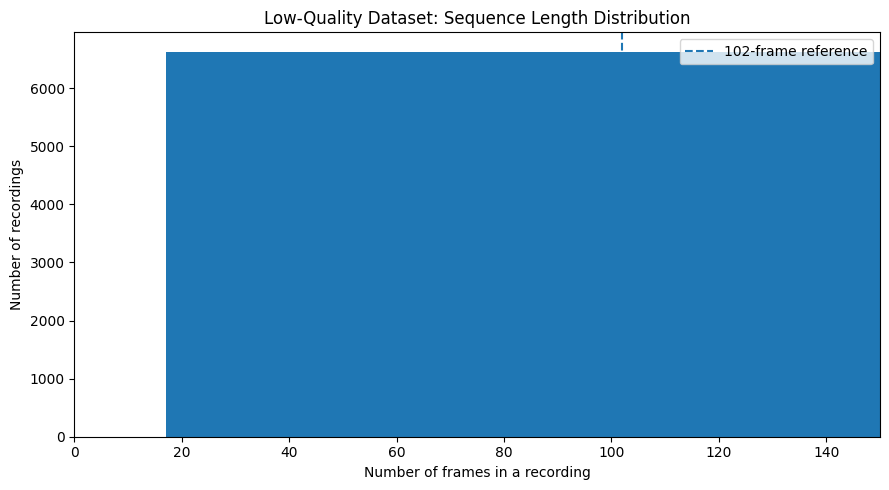

Note: The histogram is limited to 150 frames for readability.
Recordings longer than 150 frames: 29


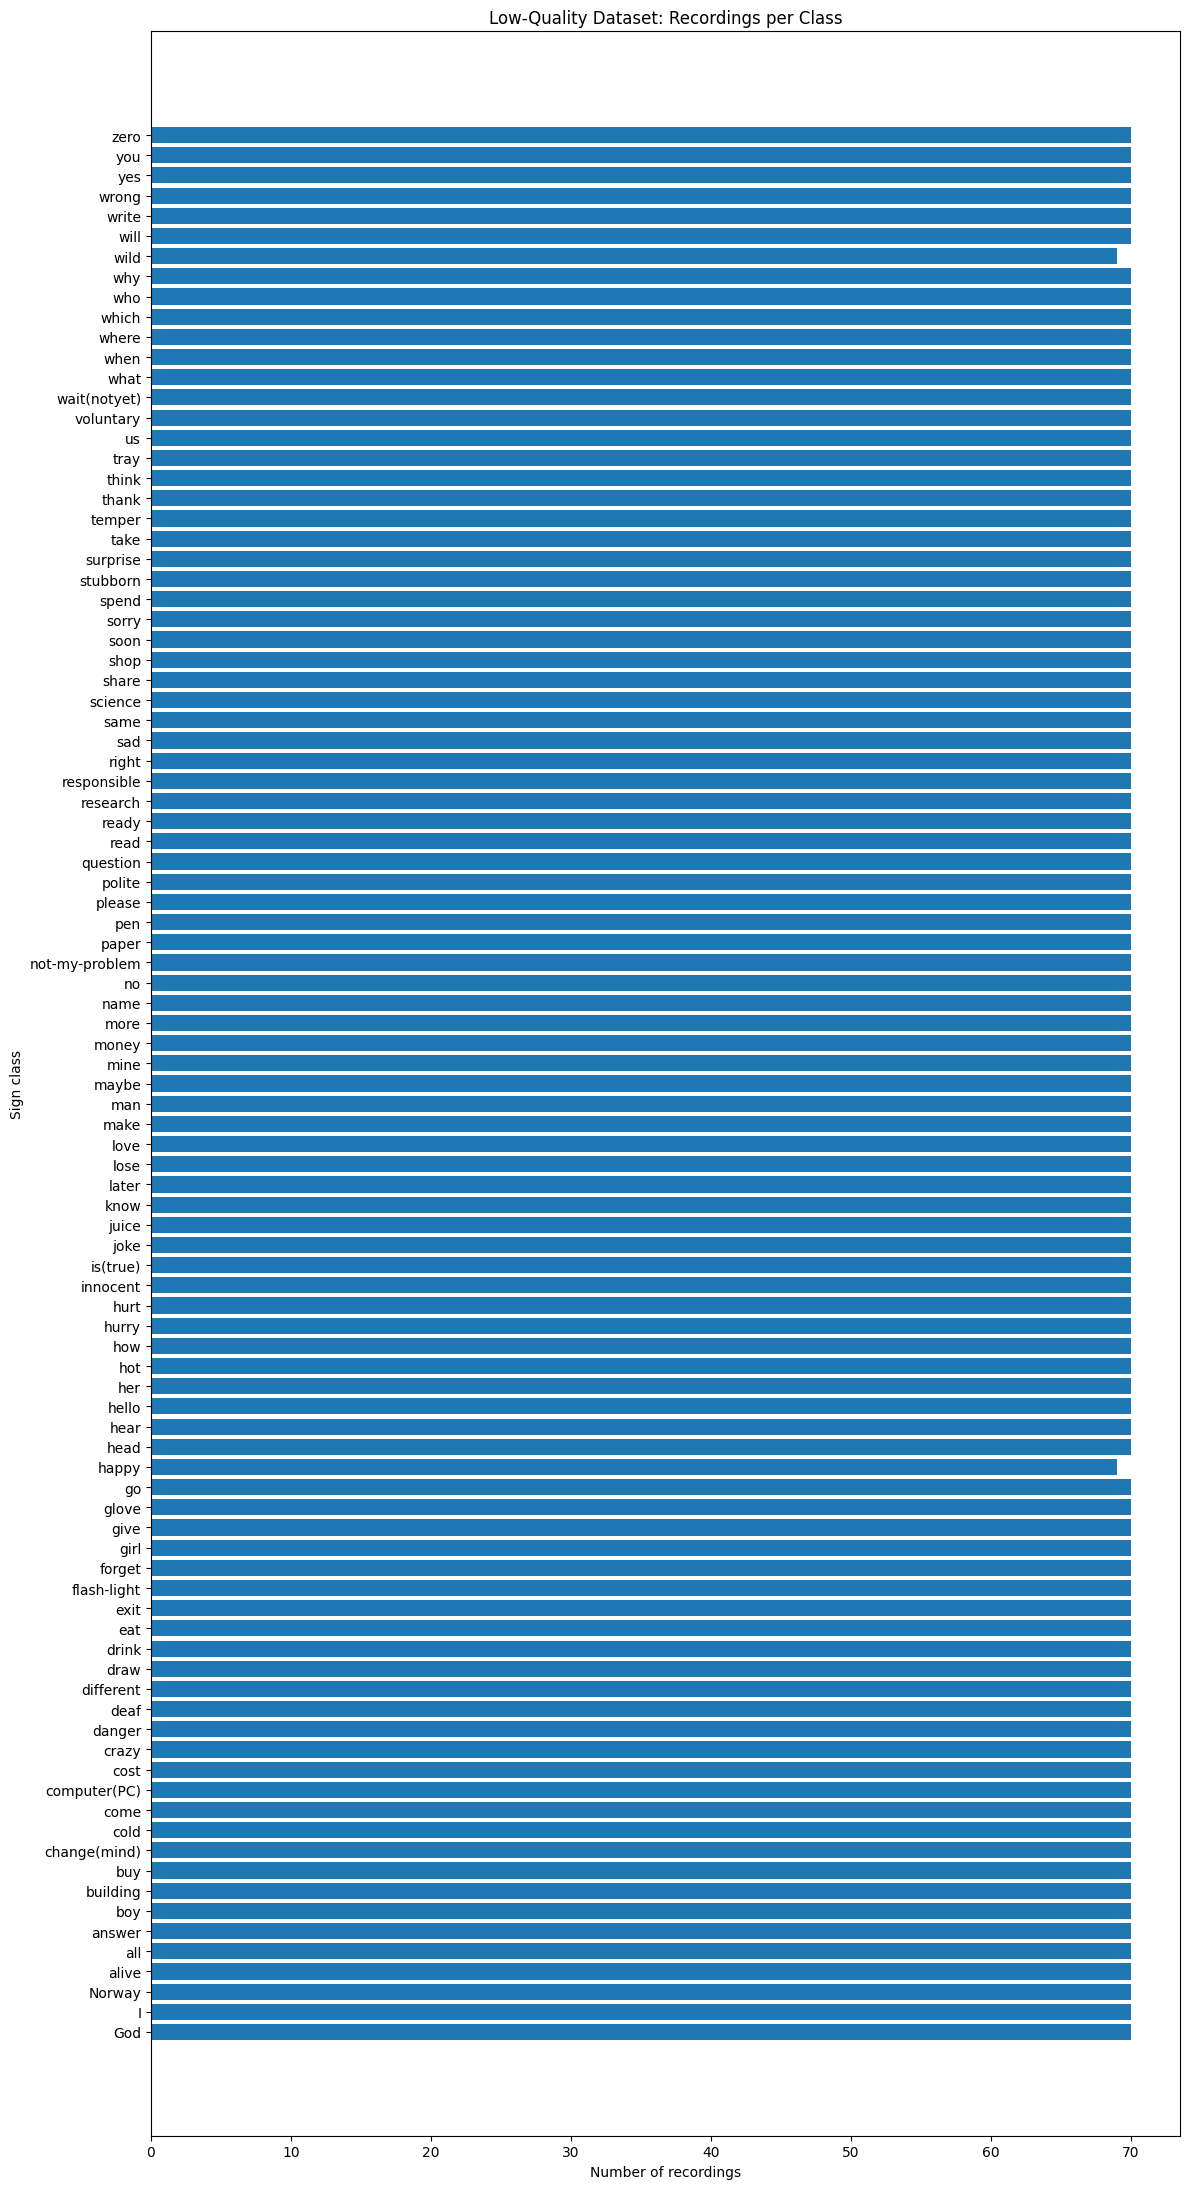

Number of classes: 95
Minimum recordings per class: 69
Maximum recordings per class: 70


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

# Plot 1: Original Low-Quality sequence-length distribution
# length_df was created during the earlier length-statistics check.
plt.figure(figsize=(9, 5))
plt.hist(length_df["length"], bins=30)
plt.axvline(102, linestyle="--", label="102-frame reference")
plt.xlim(0, 150)
plt.xlabel("Number of frames in a recording")
plt.ylabel("Number of recordings")
plt.title("Low-Quality Dataset: Sequence Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

print("Note: The histogram is limited to 150 frames for readability.")
print("Recordings longer than 150 frames:",
      int((length_df["length"] > 150).sum()))

# Plot 2: Low-Quality recordings per sign class
class_counts = Counter(y_low)
sorted_counts = sorted(class_counts.items(), key=lambda item: item[0])

labels = [item[0] for item in sorted_counts]
counts = [item[1] for item in sorted_counts]

plt.figure(figsize=(12, 22))
plt.barh(labels, counts)
plt.xlabel("Number of recordings")
plt.ylabel("Sign class")
plt.title("Low-Quality Dataset: Recordings per Class")
plt.tight_layout()
plt.show()

print("Number of classes:", len(class_counts))
print("Minimum recordings per class:", min(class_counts.values()))
print("Maximum recordings per class:", max(class_counts.values()))


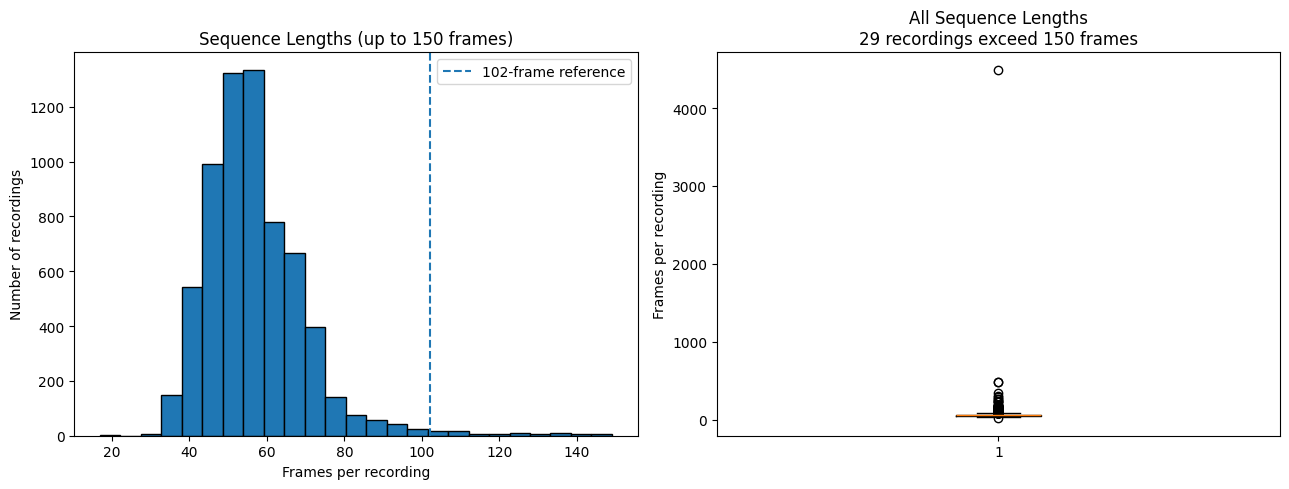

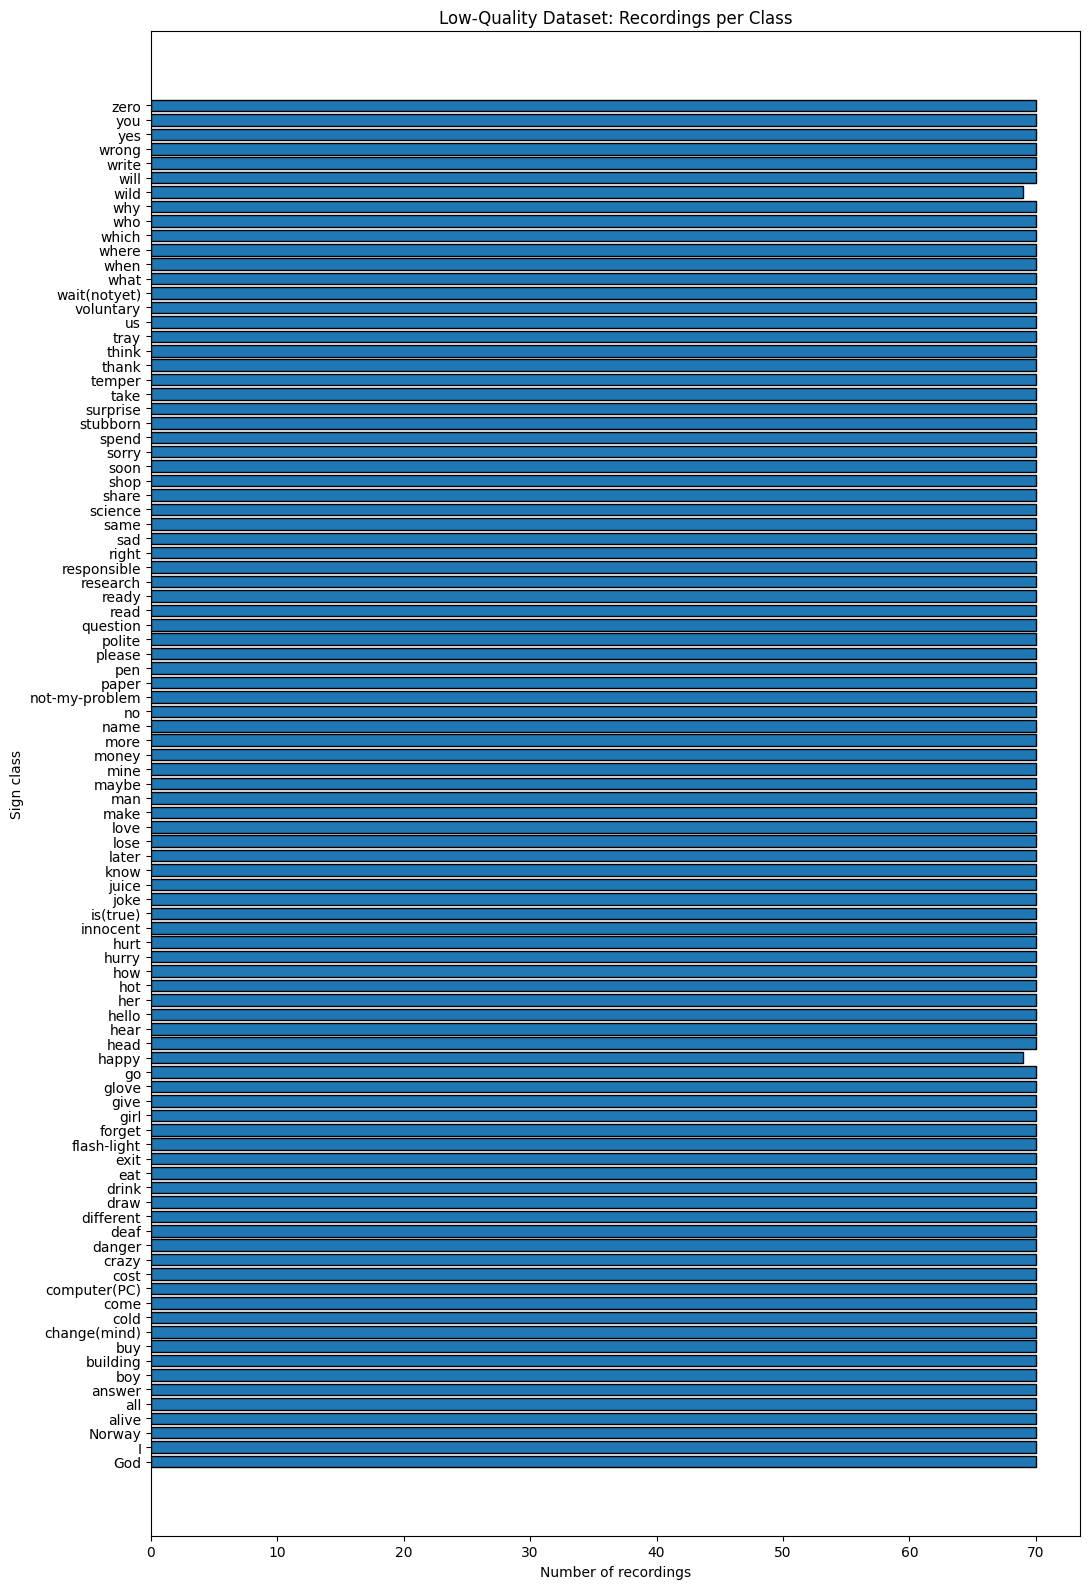

Both plots saved to Google Drive:
- low_quality_sequence_lengths.png
- low_quality_class_distribution.png

Long recordings (>150 frames): 29


In [ ]:

import os
import matplotlib.pyplot as plt
from collections import Counter

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"
os.makedirs(project_dir, exist_ok=True)

# Plot 1: Sequence lengths, with long outliers reported separately
lengths = length_df["length"].to_numpy()
long_count = int((lengths > 150).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(lengths[lengths <= 150], bins=25, edgecolor="black")
axes[0].axvline(102, linestyle="--", label="102-frame reference")
axes[0].set_xlabel("Frames per recording")
axes[0].set_ylabel("Number of recordings")
axes[0].set_title("Sequence Lengths (up to 150 frames)")
axes[0].legend()

axes[1].boxplot(lengths, vert=True)
axes[1].set_ylabel("Frames per recording")
axes[1].set_title(f"All Sequence Lengths\n{long_count} recordings exceed 150 frames")

fig.tight_layout()
fig.savefig(
    os.path.join(project_dir, "low_quality_sequence_lengths.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot 2: Recordings per class
class_counts = Counter(y_low)
sorted_counts = sorted(class_counts.items())

labels = [label for label, count in sorted_counts]
counts = [count for label, count in sorted_counts]

plt.figure(figsize=(11, 16))
plt.barh(labels, counts, edgecolor="black")
plt.xlabel("Number of recordings")
plt.ylabel("Sign class")
plt.title("Low-Quality Dataset: Recordings per Class")
plt.tight_layout()

plt.savefig(
    os.path.join(project_dir, "low_quality_class_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Both plots saved to Google Drive:")
print("- low_quality_sequence_lengths.png")
print("- low_quality_class_distribution.png")
print("\nLong recordings (>150 frames):", long_count)


In [ ]:

import os
import json
import numpy as np

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

# Check all saved split files
expected_shapes = {
    "Xh_train.npy": (2052, 136, 22),
    "Xh_test.npy": (513, 136, 22),
    "yh_train.npy": (2052,),
    "yh_test.npy": (513,),
    "Xl_train.npy": (5318, 100, 8),
    "Xl_test.npy": (1330, 100, 8),
    "yl_train.npy": (5318,),
    "yl_test.npy": (1330,),
}

print("SAVED DATA VERIFICATION")
print("-" * 35)

for filename, expected_shape in expected_shapes.items():
    path = os.path.join(project_dir, filename)
    assert os.path.isfile(path), f"Missing file: {filename}"

    array = np.load(path, allow_pickle=False)
    assert array.shape == expected_shape, (
        f"{filename}: expected {expected_shape}, got {array.shape}"
    )

    print(f"{filename}: OK {array.shape}")

# Verify experiment configuration
config_path = os.path.join(project_dir, "experiment_config.json")
assert os.path.isfile(config_path)

with open(config_path, "r") as f:
    config = json.load(f)

print("\nExperiment configuration: OK")
print("Random seed:", config["random_state"])
print("Test size:", config["test_size"])

# Check saved visualizations
for filename in [
    "low_quality_sequence_lengths.png",
    "low_quality_class_distribution.png",
]:
    path = os.path.join(project_dir, filename)
    print(f"{filename}: {'OK' if os.path.isfile(path) else 'MISSING'}")

print("\nFinal data verification completed.")
print("No model training performed.")


SAVED DATA VERIFICATION
-----------------------------------
Xh_train.npy: OK (2052, 136, 22)
Xh_test.npy: OK (513, 136, 22)


ValueError: Object arrays cannot be loaded when allow_pickle=False

In [ ]:

import os
import json
import numpy as np

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

expected_shapes = {
    "Xh_train.npy": (2052, 136, 22),
    "Xh_test.npy": (513, 136, 22),
    "yh_train.npy": (2052,),
    "yh_test.npy": (513,),
    "Xl_train.npy": (5318, 100, 8),
    "Xl_test.npy": (1330, 100, 8),
    "yl_train.npy": (5318,),
    "yl_test.npy": (1330,),
}

print("SAVED DATA VERIFICATION")
print("-" * 35)

for filename, expected_shape in expected_shapes.items():
    path = os.path.join(project_dir, filename)
    assert os.path.isfile(path), f"Missing file: {filename}"

    # Feature arrays are numeric; label arrays may use object dtype.
    if filename.startswith("X"):
        array = np.load(path, allow_pickle=False)
        assert np.issubdtype(array.dtype, np.number)
        assert np.isfinite(array).all()
    else:
        array = np.load(path, allow_pickle=True)
        assert all(isinstance(label, (str, np.str_)) for label in array)

    assert array.shape == expected_shape, (
        f"{filename}: expected {expected_shape}, got {array.shape}"
    )

    print(f"{filename}: OK {array.shape}")

config_path = os.path.join(project_dir, "experiment_config.json")
with open(config_path, "r") as f:
    config = json.load(f)

print("\nExperiment configuration: OK")
print("Random seed:", config["random_state"])
print("Test size:", config["test_size"])

for filename in [
    "low_quality_sequence_lengths.png",
    "low_quality_class_distribution.png",
]:
    path = os.path.join(project_dir, filename)
    print(f"{filename}: {'OK' if os.path.isfile(path) else 'MISSING'}")

print("\nVerification completed.")
print("No model training performed.")


SAVED DATA VERIFICATION
-----------------------------------
Xh_train.npy: OK (2052, 136, 22)
Xh_test.npy: OK (513, 136, 22)
yh_train.npy: OK (2052,)
yh_test.npy: OK (513,)
Xl_train.npy: OK (5318, 100, 8)
Xl_test.npy: OK (1330, 100, 8)
yl_train.npy: OK (5318,)
yl_test.npy: OK (1330,)

Experiment configuration: OK
Random seed: 42
Test size: 0.2
low_quality_sequence_lengths.png: OK
low_quality_class_distribution.png: OK

Verification completed.
No model training performed.


In [ ]:

import os
import json
import numpy as np

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

# Mount Google Drive if it is not already mounted
from google.colab import drive
drive.mount("/content/drive")

# Load the saved train/test splits
Xh_train = np.load(os.path.join(project_dir, "Xh_train.npy"))
Xh_test  = np.load(os.path.join(project_dir, "Xh_test.npy"))
yh_train = np.load(os.path.join(project_dir, "yh_train.npy"), allow_pickle=True)
yh_test  = np.load(os.path.join(project_dir, "yh_test.npy"), allow_pickle=True)

Xl_train = np.load(os.path.join(project_dir, "Xl_train.npy"))
Xl_test  = np.load(os.path.join(project_dir, "Xl_test.npy"))
yl_train = np.load(os.path.join(project_dir, "yl_train.npy"), allow_pickle=True)
yl_test  = np.load(os.path.join(project_dir, "yl_test.npy"), allow_pickle=True)

# Load experiment configuration
with open(os.path.join(project_dir, "experiment_config.json"), "r") as f:
    experiment_config = json.load(f)

print("HIGH-QUALITY DATA")
print("Train:", Xh_train.shape, yh_train.shape)
print("Test: ", Xh_test.shape, yh_test.shape)
print("Classes:", len(np.unique(yh_train)))

print("\nLOW-QUALITY DATA")
print("Train:", Xl_train.shape, yl_train.shape)
print("Test: ", Xl_test.shape, yl_test.shape)
print("Classes:", len(np.unique(yl_train)))

# Verify the loaded arrays
assert Xh_train.shape == (2052, 136, 22)
assert Xh_test.shape == (513, 136, 22)
assert Xl_train.shape == (5318, 100, 8)
assert Xl_test.shape == (1330, 100, 8)

assert len(np.unique(yh_train)) == 95
assert len(np.unique(yh_test)) == 95
assert len(np.unique(yl_train)) == 95
assert len(np.unique(yl_test)) == 95

assert np.isfinite(Xh_train).all() and np.isfinite(Xh_test).all()
assert np.isfinite(Xl_train).all() and np.isfinite(Xl_test).all()

print("\nAll saved datasets loaded and verified successfully.")
print("No model training performed yet.")


Mounted at /content/drive
HIGH-QUALITY DATA
Train: (2052, 136, 22) (2052,)
Test:  (513, 136, 22) (513,)
Classes: 95

LOW-QUALITY DATA
Train: (5318, 100, 8) (5318,)
Test:  (1330, 100, 8) (1330,)
Classes: 95

All saved datasets loaded and verified successfully.
No model training performed yet.


In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Folder for model results
results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Flatten each sequence for traditional ML models
Xh_train_flat = Xh_train.reshape(len(Xh_train), -1)
Xh_test_flat = Xh_test.reshape(len(Xh_test), -1)

Xl_train_flat = Xl_train.reshape(len(Xl_train), -1)
Xl_test_flat = Xl_test.reshape(len(Xl_test), -1)

print("Flattened feature shapes")
print("High-Quality train/test:", Xh_train_flat.shape, Xh_test_flat.shape)
print("Low-Quality train/test: ", Xl_train_flat.shape, Xl_test_flat.shape)

# Define model configurations (not fitted yet)
model_configs = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ),
    "SVM (RBF)": SVC(
        kernel="rbf",
        C=1.0,
        cache_size=1000
    )
}

print("\nModels configured:")
for name in model_configs:
    print("-", name)

print("\nNo models have been fitted yet.")


Flattened feature shapes
High-Quality train/test: (2052, 2992) (513, 2992)
Low-Quality train/test:  (5318, 800) (1330, 800)

Models configured:
- Logistic Regression
- SVM (RBF)

No models have been fitted yet.


In [ ]:

import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Build the pipeline: fit scaling only on training data
lr_high = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

print("Training Logistic Regression on High-Quality data...")
start_time = time.time()

lr_high.fit(Xh_train_flat, yh_train)

training_time = time.time() - start_time

# Evaluate on the held-out test set
yh_pred_lr = lr_high.predict(Xh_test_flat)

lr_high_metrics = {
    "Dataset": "High-Quality",
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(yh_test, yh_pred_lr),
    "Precision_macro": precision_score(
        yh_test, yh_pred_lr, average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        yh_test, yh_pred_lr, average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        yh_test, yh_pred_lr, average="macro", zero_division=0
    ),
    "Training_time_seconds": training_time
}

print("\nHIGH-QUALITY LOGISTIC REGRESSION RESULTS")
print("-" * 45)

for metric, value in lr_high_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


Training Logistic Regression on High-Quality data...

HIGH-QUALITY LOGISTIC REGRESSION RESULTS
---------------------------------------------
Dataset: High-Quality
Model: Logistic Regression
Accuracy: 0.9571
Precision_macro: 0.9614
Recall_macro: 0.9579
F1_macro: 0.9567
Training_time_seconds: 9.7030


In [ ]:

import os
import pandas as pd
import joblib

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save the metrics
lr_results_path = os.path.join(
    results_dir, "logistic_regression_high_quality.csv"
)

pd.DataFrame([lr_high_metrics]).to_csv(
    lr_results_path, index=False
)

# Save the fitted pipeline for later use
lr_model_path = os.path.join(
    results_dir, "logistic_regression_high_quality.joblib"
)

joblib.dump(lr_high, lr_model_path)

print("Saved Logistic Regression results:")
print(lr_results_path)
print(lr_model_path)
print("\nSaved test metrics:")
print(pd.DataFrame([lr_high_metrics]).to_string(index=False))



Saved Logistic Regression results:
/content/drive/MyDrive/Sign_Language_Temporal_Classification/results/logistic_regression_high_quality.csv
/content/drive/MyDrive/Sign_Language_Temporal_Classification/results/logistic_regression_high_quality.joblib

Saved test metrics:
     Dataset               Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Training_time_seconds
High-Quality Logistic Regression  0.957115         0.961429      0.957895  0.956715               9.702989


In [ ]:

import time
import os
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_high = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        cache_size=1000
    ))
])

print("Training SVM on High-Quality data...")
start_time = time.time()

svm_high.fit(Xh_train_flat, yh_train)

svm_training_time = time.time() - start_time

print("Training completed in", round(svm_training_time, 2), "seconds.")
print("Evaluating on the held-out test set...")

yh_pred_svm = svm_high.predict(Xh_test_flat)

svm_high_metrics = {
    "Dataset": "High-Quality",
    "Model": "SVM (RBF)",
    "Accuracy": accuracy_score(yh_test, yh_pred_svm),
    "Precision_macro": precision_score(
        yh_test, yh_pred_svm, average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        yh_test, yh_pred_svm, average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        yh_test, yh_pred_svm, average="macro", zero_division=0
    ),
    "Training_time_seconds": svm_training_time
}

print("\nHIGH-QUALITY SVM RESULTS")
print("-" * 35)

for metric, value in svm_high_metrics.items():
    if isinstance(value, (float, int)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


Training SVM on High-Quality data...
Training completed in 10.04 seconds.
Evaluating on the held-out test set...

HIGH-QUALITY SVM RESULTS
-----------------------------------
Dataset: High-Quality
Model: SVM (RBF)
Accuracy: 0.7407
Precision_macro: 0.8104
Recall_macro: 0.7460
F1_macro: 0.7491
Training_time_seconds: 10.0414


In [ ]:

import os
import joblib
import pandas as pd

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save SVM metrics
svm_results_path = os.path.join(
    results_dir, "svm_high_quality.csv"
)
pd.DataFrame([svm_high_metrics]).to_csv(
    svm_results_path, index=False
)

# Save the fitted SVM pipeline
svm_model_path = os.path.join(
    results_dir, "svm_high_quality.joblib"
)
joblib.dump(svm_high, svm_model_path)

# Save an updated combined comparison
comparison_path = os.path.join(
    results_dir, "baseline_comparison.csv"
)
pd.DataFrame([
    lr_high_metrics,
    svm_high_metrics
]).to_csv(comparison_path, index=False)

print("SVM results saved.")
print("Combined comparison saved to:", comparison_path)
print("\nCurrent comparison:")
print(
    pd.DataFrame([lr_high_metrics, svm_high_metrics])[
        ["Dataset", "Model", "Accuracy", "Precision_macro",
         "Recall_macro", "F1_macro", "Training_time_seconds"]
    ].round(4).to_string(index=False)
)


SVM results saved.
Combined comparison saved to: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/baseline_comparison.csv

Current comparison:
     Dataset               Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Training_time_seconds
High-Quality Logistic Regression    0.9571           0.9614        0.9579    0.9567                 9.7030
High-Quality           SVM (RBF)    0.7407           0.8104        0.7460    0.7491                10.0414


In [ ]:

import time
import os
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lr_low = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

print("Training Logistic Regression on Low-Quality data...")
start_time = time.time()

lr_low.fit(Xl_train_flat, yl_train)

lr_low_training_time = time.time() - start_time

print("Training completed in", round(lr_low_training_time, 2), "seconds.")

yl_pred_lr = lr_low.predict(Xl_test_flat)

lr_low_metrics = {
    "Dataset": "Low-Quality",
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(yl_test, yl_pred_lr),
    "Precision_macro": precision_score(
        yl_test, yl_pred_lr, average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        yl_test, yl_pred_lr, average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        yl_test, yl_pred_lr, average="macro", zero_division=0
    ),
    "Training_time_seconds": lr_low_training_time
}

print("\nLOW-QUALITY LOGISTIC REGRESSION RESULTS")
print("-" * 45)

for metric, value in lr_low_metrics.items():
    if isinstance(value, (float, int)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


Training Logistic Regression on Low-Quality data...
Training completed in 32.99 seconds.

LOW-QUALITY LOGISTIC REGRESSION RESULTS
---------------------------------------------
Dataset: Low-Quality
Model: Logistic Regression
Accuracy: 0.4692
Precision_macro: 0.4756
Recall_macro: 0.4692
F1_macro: 0.4638
Training_time_seconds: 32.9889


In [ ]:

import os
import joblib
import pandas as pd

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save metrics
lr_low_results_path = os.path.join(
    results_dir, "logistic_regression_low_quality.csv"
)
pd.DataFrame([lr_low_metrics]).to_csv(
    lr_low_results_path, index=False
)

# Save fitted model pipeline
lr_low_model_path = os.path.join(
    results_dir, "logistic_regression_low_quality.joblib"
)
joblib.dump(lr_low, lr_low_model_path)

# Update comparison with all three completed runs
all_baseline_metrics = [
    lr_high_metrics,
    svm_high_metrics,
    lr_low_metrics
]

comparison_path = os.path.join(
    results_dir, "baseline_comparison.csv"
)
comparison_df = pd.DataFrame(all_baseline_metrics)
comparison_df.to_csv(comparison_path, index=False)

print("Low-Quality Logistic Regression saved.")
print("Combined comparison saved.")
print("\nCurrent baseline comparison:")
print(
    comparison_df[
        ["Dataset", "Model", "Accuracy", "Precision_macro",
         "Recall_macro", "F1_macro", "Training_time_seconds"]
    ].round(4).to_string(index=False)
)


Low-Quality Logistic Regression saved.
Combined comparison saved.

Current baseline comparison:
     Dataset               Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Training_time_seconds
High-Quality Logistic Regression    0.9571           0.9614        0.9579    0.9567                 9.7030
High-Quality           SVM (RBF)    0.7407           0.8104        0.7460    0.7491                10.0414
 Low-Quality Logistic Regression    0.4692           0.4756        0.4692    0.4638                32.9889


In [ ]:

import time
import os
import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_low = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        cache_size=1000
    ))
])

print("Training SVM on Low-Quality data...")
start_time = time.time()

svm_low.fit(Xl_train_flat, yl_train)

svm_low_training_time = time.time() - start_time

print("Training completed in", round(svm_low_training_time, 2), "seconds.")
print("Evaluating on the held-out test set...")

yl_pred_svm = svm_low.predict(Xl_test_flat)

svm_low_metrics = {
    "Dataset": "Low-Quality",
    "Model": "SVM (RBF)",
    "Accuracy": accuracy_score(yl_test, yl_pred_svm),
    "Precision_macro": precision_score(
        yl_test, yl_pred_svm, average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        yl_test, yl_pred_svm, average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        yl_test, yl_pred_svm, average="macro", zero_division=0
    ),
    "Training_time_seconds": svm_low_training_time
}

print("\nLOW-QUALITY SVM RESULTS")
print("-" * 35)

for metric, value in svm_low_metrics.items():
    if isinstance(value, (float, int)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


Training SVM on Low-Quality data...
Training completed in 13.88 seconds.
Evaluating on the held-out test set...

LOW-QUALITY SVM RESULTS
-----------------------------------
Dataset: Low-Quality
Model: SVM (RBF)
Accuracy: 0.6414
Precision_macro: 0.6614
Recall_macro: 0.6414
F1_macro: 0.6391
Training_time_seconds: 13.8844


In [ ]:

import os
import joblib
import pandas as pd

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save Low-Quality SVM metrics and fitted model
pd.DataFrame([svm_low_metrics]).to_csv(
    os.path.join(results_dir, "svm_low_quality.csv"),
    index=False
)

joblib.dump(
    svm_low,
    os.path.join(results_dir, "svm_low_quality.joblib")
)

# Combine all four completed experiments
all_baseline_metrics = [
    lr_high_metrics,
    svm_high_metrics,
    lr_low_metrics,
    svm_low_metrics
]

comparison_df = pd.DataFrame(all_baseline_metrics)

comparison_path = os.path.join(
    results_dir, "baseline_comparison.csv"
)
comparison_df.to_csv(comparison_path, index=False)

print("All four baseline results saved.")
print("\nBASELINE COMPARISON")
print(
    comparison_df[
        ["Dataset", "Model", "Accuracy", "Precision_macro",
         "Recall_macro", "F1_macro", "Training_time_seconds"]
    ].round(4).to_string(index=False)
)
print("\nSaved to:", comparison_path)


All four baseline results saved.

BASELINE COMPARISON
     Dataset               Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Training_time_seconds
High-Quality Logistic Regression    0.9571           0.9614        0.9579    0.9567                 9.7030
High-Quality           SVM (RBF)    0.7407           0.8104        0.7460    0.7491                10.0414
 Low-Quality Logistic Regression    0.4692           0.4756        0.4692    0.4638                32.9889
 Low-Quality           SVM (RBF)    0.6414           0.6614        0.6414    0.6391                13.8844

Saved to: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/baseline_comparison.csv


In [ ]:

import tensorflow as tf
import numpy as np

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpus))
print("GPU devices:", gpus if gpus else "None — CPU mode")

print("\nLSTM input shapes:")
print("High-Quality train/test:", Xh_train.shape, Xh_test.shape)
print("Low-Quality train/test: ", Xl_train.shape, Xl_test.shape)

print("\nLabel classes:")
print("High-Quality:", len(np.unique(yh_train)))
print("Low-Quality:", len(np.unique(yl_train)))

print("\nEnvironment check complete. No LSTM training performed.")


TensorFlow version: 2.21.0
GPU available: False
GPU devices: None — CPU mode

LSTM input shapes:
High-Quality train/test: (2052, 136, 22) (513, 136, 22)
Low-Quality train/test:  (5318, 100, 8) (1330, 100, 8)

Label classes:
High-Quality: 95
Low-Quality: 95

Environment check complete. No LSTM training performed.


In [ ]:

import os
import json
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Encode labels using training labels only
encoder_high = LabelEncoder()
yh_train_enc = encoder_high.fit_transform(yh_train)
yh_test_enc = encoder_high.transform(yh_test)

encoder_low = LabelEncoder()
yl_train_enc = encoder_low.fit_transform(yl_train)
yl_test_enc = encoder_low.transform(yl_test)

assert len(encoder_high.classes_) == 95
assert len(encoder_low.classes_) == 95

# Normalize features using training data only
# Statistics are computed separately for each feature.
high_mean = Xh_train.mean(axis=(0, 1), keepdims=True)
high_std = Xh_train.std(axis=(0, 1), keepdims=True)
high_std[high_std < 1e-7] = 1.0

Xh_train_lstm = ((Xh_train - high_mean) / high_std).astype(np.float32)
Xh_test_lstm = ((Xh_test - high_mean) / high_std).astype(np.float32)

low_mean = Xl_train.mean(axis=(0, 1), keepdims=True)
low_std = Xl_train.std(axis=(0, 1), keepdims=True)
low_std[low_std < 1e-7] = 1.0

Xl_train_lstm = ((Xl_train - low_mean) / low_std).astype(np.float32)
Xl_test_lstm = ((Xl_test - low_mean) / low_std).astype(np.float32)

# Define a reusable LSTM model builder
def build_lstm(input_shape, num_classes=95):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(64),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Build models to verify architecture (not fitted)
lstm_high = build_lstm((136, 22))
lstm_low = build_lstm((100, 8))

print("Encoded classes:")
print("High-Quality:", len(encoder_high.classes_))
print("Low-Quality:", len(encoder_low.classes_))

print("\nPrepared LSTM inputs:")
print("High train/test:", Xh_train_lstm.shape, Xh_test_lstm.shape)
print("Low train/test: ", Xl_train_lstm.shape, Xl_test_lstm.shape)

print("\nHigh-Quality model parameters:", lstm_high.count_params())
print("Low-Quality model parameters:", lstm_low.count_params())

print("\nInputs normalized and models configured.")
print("No LSTM training performed.")


Encoded classes:
High-Quality: 95
Low-Quality: 95

Prepared LSTM inputs:
High train/test: (2052, 136, 22) (513, 136, 22)
Low train/test:  (5318, 100, 8) (1330, 100, 8)

High-Quality model parameters: 32607
Low-Quality model parameters: 29023

Inputs normalized and models configured.
No LSTM training performed.


In [ ]:

import os
import time
import tensorflow as tf
import numpy as np

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save the best model based on validation loss
high_checkpoint_path = os.path.join(
    results_dir, "lstm_high_quality_best.keras"
)

callbacks_high = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        high_checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Training High-Quality LSTM on CPU...")
start_time = time.time()

history_high = lstm_high.fit(
    Xh_train_lstm,
    yh_train_enc,
    validation_split=0.15,
    epochs=5,
    batch_size=32,
    callbacks=callbacks_high,
    verbose=1
)

lstm_high_training_time = time.time() - start_time

print("\nTraining finished.")
print("Training time:", round(lstm_high_training_time, 2), "seconds")
print("Epochs completed:", len(history_high.history["loss"]))
print("Best validation accuracy:",
      round(max(history_high.history["val_accuracy"]), 4))
print("Best validation loss:",
      round(min(history_high.history["val_loss"]), 4))
print("Best model saved to:", high_checkpoint_path)


Training High-Quality LSTM on CPU...
Epoch 1/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.0112 - loss: 4.5688
Epoch 1: val_loss improved from None to 4.56676, saving model to /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_best.keras
55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.0080 - loss: 4.5709 - val_accuracy: 0.0130 - val_loss: 4.5668
Epoch 2/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.0114 - loss: 4.5458
Epoch 2: val_loss did not improve from 4.56676
55/55 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.0086 - loss: 4.5522 - val_accuracy: 0.0065 - val_loss: 4.5693
Epoch 3/5
54/55 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.0186 - loss: 4.5362
Epoch 3: val_loss did not improve from 4.56676
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.0166 - loss: 4.5390 - val_accuracy:

In [ ]:

import numpy as np
import pandas as pd

print("LABEL ENCODING CHECK")
print("-" * 35)

print("High-Quality classes:", len(encoder_high.classes_))
print("Encoded training labels:",
      np.unique(yh_train_enc).min(),
      "to",
      np.unique(yh_train_enc).max())
print("Encoded test labels:",
      np.unique(yh_test_enc).min(),
      "to",
      np.unique(yh_test_enc).max())

print("\nFirst 10 class mappings:")
for i, label in enumerate(encoder_high.classes_[:10]):
    print(i, "->", label)

print("\nHIGH-QUALITY LSTM LEARNING CURVE")
print("-" * 35)

history_df = pd.DataFrame(history_high.history)
print(history_df.round(4).to_string(index=True))

print("\nCheckpoint exists:", os.path.isfile(high_checkpoint_path))
print("No additional training performed.")


LABEL ENCODING CHECK
-----------------------------------
High-Quality classes: 95
Encoded training labels: 0 to 94
Encoded test labels: 0 to 94

First 10 class mappings:
0 -> God
1 -> I
2 -> Norway
3 -> alive
4 -> all
5 -> answer
6 -> boy
7 -> building
8 -> buy
9 -> change mind

HIGH-QUALITY LSTM LEARNING CURVE
-----------------------------------
   accuracy    loss  val_accuracy  val_loss
0    0.0080  4.5709        0.0130    4.5668
1    0.0086  4.5522        0.0065    4.5693
2    0.0166  4.5390        0.0065    4.5753

Checkpoint exists: True
No additional training performed.


In [ ]:

import numpy as np
from collections import Counter

print("INPUT DATA CHECK")
print("-" * 35)

print("All normalized training values finite:",
      np.isfinite(Xh_train_lstm).all())
print("All normalized test values finite:",
      np.isfinite(Xh_test_lstm).all())

print("\nNormalized training statistics:")
print("Mean:", round(float(Xh_train_lstm.mean()), 4))
print("Standard deviation:", round(float(Xh_train_lstm.std()), 4))
print("Minimum:", round(float(Xh_train_lstm.min()), 4))
print("Maximum:", round(float(Xh_train_lstm.max()), 4))

print("\nFeature variation:")
feature_stds = Xh_train_lstm.std(axis=(0, 1))
print("Features with near-zero variation:",
      int((feature_stds < 1e-6).sum()), "of", len(feature_stds))
print("Per-feature standard deviations:")
print(np.round(feature_stds, 3))

print("\nLabel balance:")
counts = Counter(yh_train_enc)
print("Number of classes:", len(counts))
print("Minimum samples per class:", min(counts.values()))
print("Maximum samples per class:", max(counts.values()))

print("\nFirst training sequence shape:",
      Xh_train_lstm[0].shape)
print("First training label:",
      int(yh_train_enc[0]),
      "->", encoder_high.inverse_transform([yh_train_enc[0]])[0])

print("\nDiagnostic complete. No training performed.")


INPUT DATA CHECK
-----------------------------------
All normalized training values finite: True
All normalized test values finite: True

Normalized training statistics:
Mean: -0.0
Standard deviation: 1.0
Minimum: -7.6714
Maximum: 7.8801

Feature variation:
Features with near-zero variation: 0 of 22
Per-feature standard deviations:
[1.    1.    1.    1.    1.    1.    1.001 1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.    1.    1.    1.    1.    0.999]

Label balance:
Number of classes: 95
Minimum samples per class: 21
Maximum samples per class: 22

First training sequence shape: (136, 22)
First training label: 33 -> hot

Diagnostic complete. No training performed.


In [ ]:

import numpy as np
import tensorflow as tf

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Use a small, stratified subset of the training data
from sklearn.model_selection import train_test_split

X_debug, _, y_debug, _ = train_test_split(
    Xh_train_lstm,
    yh_train_enc,
    train_size=256,
    random_state=42,
    stratify=yh_train_enc
)

debug_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(136, 22)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(95, activation="softmax")
])

debug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Debug subset:", X_debug.shape, y_debug.shape)
print("Training on 256 examples to diagnose learning...")

debug_history = debug_model.fit(
    X_debug,
    y_debug,
    epochs=15,
    batch_size=32,
    verbose=1
)

final_debug_accuracy = debug_model.evaluate(
    X_debug, y_debug, verbose=0
)[1]

print("\nSMALL-SUBSET DIAGNOSTIC")
print("Final training accuracy:", round(float(final_debug_accuracy), 4))
print("Best training accuracy:",
      round(max(debug_history.history["accuracy"]), 4))
print("This is a training-subset diagnostic, not test accuracy.")


Debug subset: (256, 136, 22) (256,)
Training on 256 examples to diagnose learning...
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.0078 - loss: 4.5724
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.0352 - loss: 4.5290
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.0430 - loss: 4.5009
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.0586 - loss: 4.4687
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.0625 - loss: 4.4272
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.0664 - loss: 4.3729
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.0547 - loss: 4.3049
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.0586 - loss: 4.2268
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.0703 - loss: 4.1366
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0742 - loss: 4.0553
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.0859 - loss: 3.9670


In [ ]:

import os
import time
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

def build_lstm_v2(input_shape, num_classes=95):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(64, return_sequences=True),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

lstm_high_v2 = build_lstm_v2((136, 22))

high_v2_path = os.path.join(
    results_dir, "lstm_high_quality_v2_best.keras"
)

callbacks_high_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        high_v2_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Training revised High-Quality LSTM on CPU...")
start_time = time.time()

history_high_v2 = lstm_high_v2.fit(
    Xh_train_lstm,
    yh_train_enc,
    validation_split=0.15,
    epochs=15,
    batch_size=32,
    callbacks=callbacks_high_v2,
    verbose=1
)

high_v2_time = time.time() - start_time

print("\nRevised LSTM training finished.")
print("Training time:", round(high_v2_time, 2), "seconds")
print("Epochs completed:", len(history_high_v2.history["loss"]))
print("Best validation accuracy:",
      round(max(history_high_v2.history["val_accuracy"]), 4))
print("Best validation loss:",
      round(min(history_high_v2.history["val_loss"]), 4))
print("Checkpoint:", high_v2_path)


Training revised High-Quality LSTM on CPU...
Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.0173 - loss: 4.5598
Epoch 1: val_loss improved from None to 4.56083, saving model to /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_v2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_v2_best.keras
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - accuracy: 0.0115 - loss: 4.5641 - val_accuracy: 0.0000e+00 - val_loss: 4.5608
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.0139 - loss: 4.5515
Epoch 2: val_loss did not improve from 4.56083
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - accuracy: 0.0120 - loss: 4.5535 - val_accuracy: 0.0032 - val_loss: 4.5662
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.0180 - loss: 4.5455
Epoch 3: val_loss did not improve from 4.56083
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - accuracy: 0.0155 - 

In [ ]:

import os
import numpy as np
import pandas as pd

# Inspect the original flattened feature file
X_original = pd.read_csv(
    os.path.join(project_dir, "auslan_X.csv")
).to_numpy(dtype=np.float32)

print("ORIGINAL HIGH-QUALITY FEATURES")
print("-" * 40)
print("Original shape:", X_original.shape)
print("Reshaped shape:", Xh_train.shape)

# Compare a training example's flattened values to its reshaped version.
# Recover the corresponding original row using the saved split index if available.
print("\nFirst reshaped training sequence:")
print(Xh_train[0, :3, :5])

print("\nFirst 20 values from its flattened representation:")
print(Xh_train[0].reshape(-1)[:20])

print("\nCheck whether the reshape itself is internally consistent:")
example_flat = Xh_train[0].reshape(-1)
example_reshaped = Xh_train[0].reshape(136, 22).reshape(-1)
print("Flatten -> reshape -> flatten unchanged:",
      np.array_equal(example_flat, example_reshaped))

print("\nDiagnostic complete. No training performed.")


ORIGINAL HIGH-QUALITY FEATURES
----------------------------------------
Original shape: (2565, 2992)
Reshaped shape: (2052, 136, 22)

First reshaped training sequence:
[[-0.013903 -0.068703 -0.110831  0.615279  0.244572]
 [-0.013903 -0.068703 -0.110831  0.615279  0.244572]
 [-0.013055 -0.067185 -0.111143  0.615267  0.245427]]

First 20 values from its flattened representation:
[-0.013903 -0.068703 -0.110831  0.615279  0.244572  0.449989  0.
  0.030935  0.        0.        0.005606  0.038458  0.177672 -0.044088
  0.293898  0.667779  0.777166  0.        0.        0.046834]

Check whether the reshape itself is internally consistent:
Flatten -> reshape -> flatten unchanged: True

Diagnostic complete. No training performed.


In [ ]:

import os
import pandas as pd

x_path = os.path.join(project_dir, "auslan_X.csv")

# Read only the header first
header = pd.read_csv(x_path, nrows=0)
print("Number of CSV columns:", len(header.columns))
print("First 15 column names:")
print(header.columns[:15].tolist())
print("\nLast 10 column names:")
print(header.columns[-10:].tolist())

print("\nOriginal R-derived dataset note:")
print("The current CSV has 2,992 feature columns per recording.")
print("We need the source conversion logic to establish their ordering.")


Number of CSV columns: 2992
First 15 column names:
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15']

Last 10 column names:
['V2983', 'V2984', 'V2985', 'V2986', 'V2987', 'V2988', 'V2989', 'V2990', 'V2991', 'V2992']

Original R-derived dataset note:
The current CSV has 2,992 feature columns per recording.
We need the source conversion logic to establish their ordering.


In [ ]:

import os
import pandas as pd

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"

print("Available source/data files:")
for filename in sorted(os.listdir(project_dir)):
    if filename.endswith((".rda", ".R", ".r", ".csv", ".txt", ".md")):
        print("-", filename)

print("\nCSV dimensions:")
X_original = pd.read_csv(
    os.path.join(project_dir, "auslan_X.csv")
)
print(X_original.shape)

print("\nFirst row, first 30 values:")
print(X_original.iloc[0, :30].to_list())

print("\nFirst row, values around the midpoint:")
mid = X_original.shape[1] // 2
print(X_original.iloc[0, mid-5:mid+5].to_list())


Available source/data files:
- auslan_X.csv
- auslan_y.csv

CSV dimensions:
(2565, 2992)

First row, first 30 values:
[-0.097816, -0.097816, -0.10246, -0.10246, -0.10246, -0.103085, -0.103085, -0.102639, -0.102639, -0.102639, -0.105139, -0.105139, -0.105139, -0.107773, -0.107773, -0.107773, -0.107148, -0.107148, -0.107461, -0.107461, -0.107461, -0.109023, -0.109023, -0.109023, -0.111077, -0.111077, -0.111077, -0.110586, -0.110586, -0.109872]

First row, values around the midpoint:
[0.024711, 0.024711, 0.024711, 0.024711, 0.024711, 0.046011, 0.046011, 0.047708, 0.047708, 0.047708]


In [ ]:

import numpy as np

row = X_original.iloc[0].to_numpy(dtype=np.float32)
n_features = 22
n_frames = 136

print("First 15 values of block 1 (136 values per block):")
print(np.round(row[:15], 5))

print("\nFirst 15 values of block 2:")
print(np.round(row[n_frames:n_frames+15], 5))

print("\nFirst 22 values (possible first time step if time-major):")
print(np.round(row[:22], 5))

print("\nVariation within the first two blocks:")
print("Block 1 standard deviation:", round(float(np.std(row[:n_frames])), 5))
print("Block 2 standard deviation:", round(float(np.std(row[n_frames:2*n_frames])), 5))


First 15 values of block 1 (136 values per block):
[-0.09782 -0.09782 -0.10246 -0.10246 -0.10246 -0.10308 -0.10308 -0.10264
 -0.10264 -0.10264 -0.10514 -0.10514 -0.10514 -0.10777 -0.10777]

First 15 values of block 2:
[-0.12776 -0.12776 -0.12673 -0.12673 -0.12673 -0.12562 -0.12562 -0.12602
 -0.12602 -0.12602 -0.12754 -0.12754 -0.12754 -0.12772 -0.12772]

First 22 values (possible first time step if time-major):
[-0.09782 -0.09782 -0.10246 -0.10246 -0.10246 -0.10308 -0.10308 -0.10264
 -0.10264 -0.10264 -0.10514 -0.10514 -0.10514 -0.10777 -0.10777 -0.10777
 -0.10715 -0.10715 -0.10746 -0.10746 -0.10746 -0.10902]

Variation within the first two blocks:
Block 1 standard deviation: 0.00334
Block 2 standard deviation: 0.00089


In [ ]:

import numpy as np

# Candidate A: feature-major storage
X_feature_major = X_original.to_numpy(dtype=np.float32).reshape(
    -1, 22, 136
).transpose(0, 2, 1)

# Candidate B: time-major storage
X_time_major = X_original.to_numpy(dtype=np.float32).reshape(
    -1, 136, 22
)

def temporal_smoothness(X):
    return float(np.mean(np.abs(np.diff(X, axis=1))))

print("Feature-major mean temporal change:",
      round(temporal_smoothness(X_feature_major), 6))

print("Time-major mean temporal change:",
      round(temporal_smoothness(X_time_major), 6))

print("\nFeature-major first 5 frames, first 5 features:")
print(np.round(X_feature_major[0, :5, :5], 5))

print("\nTime-major first 5 frames, first 5 features:")
print(np.round(X_time_major[0, :5, :5], 5))


Feature-major mean temporal change: 0.00349
Time-major mean temporal change: 0.087081

Feature-major first 5 frames, first 5 features:
[[-0.09782 -0.12776 -0.02905  0.53798  0.24916]
 [-0.09782 -0.12776 -0.02905  0.53798  0.24916]
 [-0.10246 -0.12673 -0.02923  0.53776  0.24648]
 [-0.10246 -0.12673 -0.02923  0.53776  0.24648]
 [-0.10246 -0.12673 -0.02923  0.53776  0.24648]]

Time-major first 5 frames, first 5 features:
[[-0.09782 -0.09782 -0.10246 -0.10246 -0.10246]
 [-0.10902 -0.10902 -0.11108 -0.11108 -0.11108]
 [-0.11447 -0.11447 -0.11523 -0.11523 -0.11523]
 [-0.11318 -0.11318 -0.11389 -0.11389 -0.11389]
 [-0.11322 -0.11322 -0.11371 -0.11371 -0.11371]]


In [ ]:

import numpy as np
from sklearn.preprocessing import LabelEncoder

# Reconstruct all recordings using the feature-major candidate
X_high_candidate = X_original.to_numpy(dtype=np.float32).reshape(
    -1, 22, 136
).transpose(0, 2, 1)

# Recreate the same recording-level split (seed 42)
from sklearn.model_selection import train_test_split

y_high_all = pd.read_csv(
    os.path.join(project_dir, "auslan_y.csv")
).values.ravel()

Xh_train_candidate, Xh_test_candidate, yh_train_candidate, yh_test_candidate = (
    train_test_split(
        X_high_candidate,
        y_high_all,
        test_size=0.2,
        random_state=42,
        stratify=y_high_all
    )
)

# Normalize with training data only
feature_mean = Xh_train_candidate.mean(axis=(0, 1), keepdims=True)
feature_std = Xh_train_candidate.std(axis=(0, 1), keepdims=True)
feature_std = np.where(feature_std == 0, 1.0, feature_std)

Xh_train_candidate = (Xh_train_candidate - feature_mean) / feature_std
Xh_test_candidate = (Xh_test_candidate - feature_mean) / feature_std

print("Candidate train shape:", Xh_train_candidate.shape)
print("Candidate test shape:", Xh_test_candidate.shape)
print("Train mean:", round(float(Xh_train_candidate.mean()), 4))
print("Train std:", round(float(Xh_train_candidate.std()), 4))
print("All values finite:",
      np.isfinite(Xh_train_candidate).all() and
      np.isfinite(Xh_test_candidate).all())
print("Number of classes:", len(np.unique(y_high_all)))


Candidate train shape: (2052, 136, 22)
Candidate test shape: (513, 136, 22)
Train mean: 0.0
Train std: 1.0
All values finite: True
Number of classes: 95


In [ ]:

import os
import time
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.preprocessing import LabelEncoder

# Encode labels
encoder_high_candidate = LabelEncoder()
yh_train_candidate_enc = encoder_high_candidate.fit_transform(
    yh_train_candidate
)
yh_test_candidate_enc = encoder_high_candidate.transform(
    yh_test_candidate
)

# Build a fresh LSTM
tf.keras.utils.set_random_seed(42)

lstm_high_candidate = Sequential([
    Input(shape=(136, 22)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(95, activation="softmax")
])

lstm_high_candidate.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

candidate_model_path = os.path.join(
    results_dir, "lstm_high_quality_feature_major_best.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        candidate_model_path,
        monitor="val_loss",
        save_best_only=True
    )
]

start_time = time.time()

history_high_candidate = lstm_high_candidate.fit(
    Xh_train_candidate,
    yh_train_candidate_enc,
    validation_split=0.15,
    epochs=15,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

candidate_training_time = time.time() - start_time

print("\nTraining time:", round(candidate_training_time, 2), "seconds")
print("Best validation accuracy:",
      round(max(history_high_candidate.history["val_accuracy"]) * 100, 2), "%")
print("Saved model:", candidate_model_path)


Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.0115 - loss: 4.5641 - val_accuracy: 0.0000e+00 - val_loss: 4.5608
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 162ms/step - accuracy: 0.0120 - loss: 4.5535 - val_accuracy: 0.0032 - val_loss: 4.5662
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 173ms/step - accuracy: 0.0155 - loss: 4.5483 - val_accuracy: 0.0097 - val_loss: 4.5728
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 120ms/step - accuracy: 0.0166 - loss: 4.5351 - val_accuracy: 0.0097 - val_loss: 4.5760

Training time: 37.58 seconds
Best validation accuracy: 0.97 %
Saved model: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_feature_major_best.keras


In [ ]:

print("Candidate and original arrays:")
print("Candidate train shape:", Xh_train_candidate.shape)
print("Original train shape:", Xh_train.shape)

print("\nFirst 10 candidate labels:")
print(yh_train_candidate[:10])

print("\nFirst 10 original labels:")
print(yh_train[:10])

print("\nAre candidate and original feature arrays identical?",
      np.allclose(Xh_train_candidate, Xh_train_lstm))

print("\nCandidate model input shape:",
      lstm_high_candidate.input_shape)

print("\nCandidate model output shape:",
      lstm_high_candidate.output_shape)

print("\nCandidate training accuracy by epoch:")
print(np.round(history_high_candidate.history["accuracy"], 4))

print("\nCandidate validation accuracy by epoch:")
print(np.round(history_high_candidate.history["val_accuracy"], 4))


Candidate and original arrays:
Candidate train shape: (2052, 136, 22)
Original train shape: (2052, 136, 22)

First 10 candidate labels:
['hot' 'hear' 'pen' 'exit' 'girl' 'love' 'temper' 'buy' 'her' 'sad']

First 10 original labels:
['hot' 'hear' 'pen' 'exit' 'girl' 'love' 'temper' 'buy' 'her' 'sad']

Are candidate and original feature arrays identical? False

Candidate model input shape: (None, 136, 22)

Candidate model output shape: (None, 95)

Candidate training accuracy by epoch:
[0.0115 0.012  0.0155 0.0166]

Candidate validation accuracy by epoch:
[0.     0.0032 0.0097 0.0097]


In [ ]:

import numpy as np

# 1. Verify labels align with the original CSV
y_csv = pd.read_csv(
    os.path.join(project_dir, "auslan_y.csv")
).values.ravel()

print("CSV labels match candidate labels:",
      np.array_equal(y_csv, y_high_all))

print("Candidate labels match original training labels:",
      np.array_equal(yh_train_candidate, yh_train))

# 2. Check how many unique classes appear in the training labels
print("Unique training labels:",
      len(np.unique(yh_train_candidate)))
print("Unique encoded labels:",
      len(np.unique(yh_train_candidate_enc)))

# 3. Test whether a fresh model can memorize a tiny subset
tf.keras.utils.set_random_seed(42)

X_tiny = Xh_train_candidate[:128]
y_tiny = yh_train_candidate_enc[:128]

tiny_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(136, 22)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(95, activation="softmax")
])

tiny_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tiny_history = tiny_model.fit(
    X_tiny, y_tiny,
    epochs=10,
    batch_size=16,
    verbose=0
)

print("\nTiny-subset accuracy by epoch:")
print(np.round(tiny_history.history["accuracy"], 3))


CSV labels match candidate labels: True
Candidate labels match original training labels: True
Unique training labels: 95
Unique encoded labels: 95

Tiny-subset accuracy by epoch:
[0.008 0.031 0.062 0.055 0.062 0.062 0.062 0.078 0.102 0.102]


In [ ]:

import numpy as np
import tensorflow as tf

# Select four classes with at least two examples each
labels, counts = np.unique(yh_train_candidate_enc, return_counts=True)
selected_classes = labels[counts >= 2][:4]

selected_indices = []
for cls in selected_classes:
    indices = np.where(yh_train_candidate_enc == cls)[0][:2]
    selected_indices.extend(indices)

X_tiny4 = Xh_train_candidate[selected_indices]
y_tiny4 = yh_train_candidate_enc[selected_indices]

print("Selected classes:", selected_classes)
print("Tiny dataset shape:", X_tiny4.shape)
print("Labels:", y_tiny4)

tf.keras.utils.set_random_seed(42)

memorize_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(136, 22)),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(95, activation="softmax")
])

memorize_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

memorize_history = memorize_model.fit(
    X_tiny4, y_tiny4,
    epochs=50,
    batch_size=4,
    verbose=0
)

print("First 5 epoch accuracies:",
      np.round(memorize_history.history["accuracy"][:5], 3))
print("Last 10 epoch accuracies:",
      np.round(memorize_history.history["accuracy"][-10:], 3))
print("Final training accuracy:",
      round(memorize_history.history["accuracy"][-1] * 100, 2), "%")


Selected classes: [0 1 2 3]
Tiny dataset shape: (8, 136, 22)
Labels: [0 0 1 1 2 2 3 3]
First 5 epoch accuracies: [0.   0.   0.25 0.25 0.25]
Last 10 epoch accuracies: [0.875 0.875 1.    0.875 0.875 0.875 0.875 0.875 0.875 0.875]
Final training accuracy: 87.5 %


In [ ]:

import numpy as np

# Use a small, reproducible sample to keep computation fast
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(Xh_train_candidate), size=300, replace=False
)

X_sample = Xh_train_candidate[sample_indices]
y_sample = yh_train_candidate_enc[sample_indices]

# Flatten only for distance comparison
X_sample_flat = X_sample.reshape(len(X_sample), -1)

# Normalize each recording for distance calculation
norms = np.linalg.norm(X_sample_flat, axis=1, keepdims=True)
X_sample_unit = X_sample_flat / np.maximum(norms, 1e-8)

# Pairwise cosine distances
similarity = X_sample_unit @ X_sample_unit.T
distance = 1 - similarity

same_class = y_sample[:, None] == y_sample[None, :]
upper = np.triu(np.ones_like(same_class, dtype=bool), k=1)

same_distances = distance[same_class & upper]
different_distances = distance[(~same_class) & upper]

print("Same-class pairs:", len(same_distances))
print("Different-class pairs:", len(different_distances))
print("Mean same-class cosine distance:",
      round(float(same_distances.mean()), 4))
print("Mean different-class cosine distance:",
      round(float(different_distances.mean()), 4))


Same-class pairs: 455
Different-class pairs: 44395
Mean same-class cosine distance: 0.3148
Mean different-class cosine distance: 0.7737


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import time

# Flatten the candidate representation for a fair diagnostic
X_candidate_train_flat = Xh_train_candidate.reshape(
    len(Xh_train_candidate), -1
)
X_candidate_test_flat = Xh_test_candidate.reshape(
    len(Xh_test_candidate), -1
)

lr_candidate = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

start = time.time()
lr_candidate.fit(
    X_candidate_train_flat,
    yh_train_candidate
)
candidate_pred = lr_candidate.predict(X_candidate_test_flat)

print("Candidate Logistic Regression accuracy:",
      round(accuracy_score(yh_test_candidate, candidate_pred) * 100, 2), "%")
print("Candidate Logistic Regression macro F1:",
      round(f1_score(
          yh_test_candidate, candidate_pred,
          average="macro", zero_division=0
      ) * 100, 2), "%")
print("Training time:", round(time.time() - start, 2), "seconds")


Candidate Logistic Regression accuracy: 95.71 %
Candidate Logistic Regression macro F1: 95.67 %
Training time: 10.75 seconds


In [ ]:

print("Original representation")
print("Shape:", Xh_train_lstm.shape)
print("Mean:", round(float(Xh_train_lstm.mean()), 4))
print("Std:", round(float(Xh_train_lstm.std()), 4))

print("\nFeature-major candidate")
print("Shape:", Xh_train_candidate.shape)
print("Mean:", round(float(Xh_train_candidate.mean()), 4))
print("Std:", round(float(Xh_train_candidate.std()), 4))

print("\nOriginal and candidate first recording:")
print("Original first 3 frames, 5 features:")
print(np.round(Xh_train_lstm[0, :3, :5], 4))

print("\nCandidate first 3 frames, 5 features:")
print(np.round(Xh_train_candidate[0, :3, :5], 4))

print("\nLabel encoding consistency:",
      np.array_equal(
          encoder_high.transform(yh_train_candidate),
          yh_train_candidate_enc
      ))


Original representation
Shape: (2052, 136, 22)
Mean: -0.0
Std: 1.0

Feature-major candidate
Shape: (2052, 136, 22)
Mean: 0.0
Std: 1.0

Original and candidate first recording:
Original first 3 frames, 5 features:
[[ 0.9656  0.5558  0.4013  0.2013 -0.4718]
 [ 0.9656  0.5558  0.4013  0.2013 -0.4718]
 [ 0.9853  0.5749  0.3966  0.2012 -0.4653]]

Candidate first 3 frames, 5 features:
[[ 0.9656  0.5558  0.4013  0.2013 -0.4718]
 [ 0.9656  0.5558  0.4013  0.2013 -0.4718]
 [ 0.9853  0.5749  0.3966  0.2012 -0.4653]]

Label encoding consistency: True


In [ ]:

difference = np.abs(Xh_train_candidate - Xh_train_lstm)

print("Maximum absolute difference:",
      round(float(difference.max()), 6))
print("Mean absolute difference:",
      round(float(difference.mean()), 6))
print("Fraction of elements equal within tolerance:",
      round(float(np.isclose(
          Xh_train_candidate, Xh_train_lstm,
          atol=1e-5
      ).mean()) * 100, 2), "%")


Maximum absolute difference: 7.1e-05
Mean absolute difference: 2e-06
Fraction of elements equal within tolerance: 100.0 %


In [ ]:

import pandas as pd

history_df = pd.DataFrame(history_high_candidate.history)
history_df.index = history_df.index + 1
history_df.index.name = "Epoch"

print(history_df.round(4).to_string())

print("\nChance accuracy for 95 classes:",
      round(100 / 95, 2), "%")

print("\nFinal tiny-subset memorization accuracy:",
      round(memorize_history.history["accuracy"][-1] * 100, 2), "%")


       accuracy    loss  val_accuracy  val_loss
Epoch                                          
1        0.0115  4.5641        0.0000    4.5608
2        0.0120  4.5535        0.0032    4.5662
3        0.0155  4.5483        0.0097    4.5728
4        0.0166  4.5351        0.0097    4.5760

Chance accuracy for 95 classes: 1.05 %

Final tiny-subset memorization accuracy: 87.5 %


In [ ]:

print("Model:", lstm_high_v3.name)
print("Input shape:", lstm_high_v3.input_shape)
print("Output shape:", lstm_high_v3.output_shape)
print("Training data:", Xh_train_candidate.shape)
print("Validation split: 15%")
print("Maximum epochs: 30")
print("Learning rate: 0.0003")


NameError: name 'lstm_high_v3' is not defined

In [ ]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
import os
import time
import numpy as np

tf.keras.utils.set_random_seed(42)

lstm_high_v3 = Sequential([
    Input(shape=(136, 22)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(95, activation="softmax")
])

lstm_high_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_high_v3.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 136, 64)        │        22,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 136, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 95)             │         6,175 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,975 (167.87 KB)

 Trainable params: 42,975 (167.87 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Confirm that the required data is available
print("Training data:", Xh_train_candidate.shape)
print("Labels:", yh_train_candidate_enc.shape)

candidate_model_path = os.path.join(
    results_dir,
    "lstm_high_quality_v3_best.keras"
)

callbacks_v3 = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        candidate_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time_v3 = time.time()

history_high_v3 = lstm_high_v3.fit(
    Xh_train_candidate,
    yh_train_candidate_enc,
    validation_split=0.15,
    epochs=30,
    batch_size=64,
    callbacks=callbacks_v3,
    verbose=1
)

training_time_v3 = time.time() - start_time_v3

print("\nTraining time:", round(training_time_v3, 2), "seconds")
print(
    "Best validation accuracy:",
    round(max(history_high_v3.history["val_accuracy"]) * 100, 2),
    "%"
)
print("Best model saved at:", candidate_model_path)


Training data: (2052, 136, 22)
Labels: (2052,)
Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.0141 - loss: 4.5582
Epoch 1: val_loss improved from None to 4.56240, saving model to /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_v3_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/lstm_high_quality_v3_best.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 188ms/step - accuracy: 0.0097 - loss: 4.5617 - val_accuracy: 0.0032 - val_loss: 4.5624
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.0100 - loss: 4.5504
Epoch 2: val_loss did not improve from 4.56240
28/28 ━━━━━━━━━━━━━━━━━━━━ 6s 231ms/step - accuracy: 0.0103 - loss: 4.5549 - val_accuracy: 0.0032 - val_loss: 4.5635
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.0181 - loss: 4.5481
Epoch 3: val_loss did not improve from 4.56240
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.0161 - los

In [ ]:

import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score, classification_report

# Predict on the held-out test set
v3_probabilities = lstm_high_v3.predict(
    Xh_test_candidate, verbose=0
)
v3_predictions = np.argmax(v3_probabilities, axis=1)

print("Test accuracy:",
      round(accuracy_score(yh_test_candidate_enc, v3_predictions) * 100, 2), "%")

print("\nNumber of predicted classes:",
      len(np.unique(v3_predictions)), "out of 95")

print("\nMost common predicted classes (encoded):")
print(Counter(v3_predictions).most_common(10))

print("\nNumber of unique true test classes:",
      len(np.unique(yh_test_candidate_enc)))

print("\nFirst 20 true labels:")
print(yh_test_candidate_enc[:20])

print("\nFirst 20 predictions:")
print(v3_predictions[:20])


Test accuracy: 0.78 %

Number of predicted classes: 20 out of 95

Most common predicted classes (encoded):
[(np.int64(51), 176), (np.int64(73), 109), (np.int64(71), 52), (np.int64(28), 30), (np.int64(9), 28), (np.int64(53), 23), (np.int64(69), 21), (np.int64(3), 14), (np.int64(87), 10), (np.int64(2), 10)]

Number of unique true test classes: 95

First 20 true labels:
[56 55 62 64  1 75 41 48 64 84 24 84 42 83 43 56 58 18 24 45]

First 20 predictions:
[26 51 51 53 28 51 51 73 73 51 51 73 73 73 51 51 73 71 78 71]


In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Select 10 classes with at least 20 examples each
classes, counts = np.unique(yh_train_candidate, return_counts=True)
selected_labels = classes[counts >= 20][:10]

train_mask = np.isin(yh_train_candidate, selected_labels)
test_mask = np.isin(yh_test_candidate, selected_labels)

X_train_10 = Xh_train_candidate[train_mask]
X_test_10 = Xh_test_candidate[test_mask]

y_encoder_10 = LabelEncoder()
y_train_10 = y_encoder_10.fit_transform(yh_train_candidate[train_mask])
y_test_10 = y_encoder_10.transform(yh_test_candidate[test_mask])

print("Selected classes:", selected_labels)
print("Training shape:", X_train_10.shape)
print("Test shape:", X_test_10.shape)
print("Training examples per class:", np.bincount(y_train_10))

tf.keras.utils.set_random_seed(42)

model_10 = Sequential([
    Input(shape=(136, 22)),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(10, activation="softmax")
])

model_10.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_10 = model_10.fit(
    X_train_10, y_train_10,
    validation_split=0.15,
    epochs=20,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

pred_10 = np.argmax(model_10.predict(X_test_10, verbose=0), axis=1)

print("\nBest validation accuracy:",
      round(max(history_10.history["val_accuracy"]) * 100, 2), "%")
print("10-class test accuracy:",
      round(accuracy_score(y_test_10, pred_10) * 100, 2), "%")


Selected classes: ['God' 'I' 'Norway' 'alive' 'all' 'answer' 'boy' 'building' 'buy'
 'change mind']
Training shape: (218, 136, 22)
Test shape: (52, 136, 22)
Training examples per class: [22 21 21 22 22 22 22 22 22 22]
Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 146ms/step - accuracy: 0.1297 - loss: 2.3008 - val_accuracy: 0.1515 - val_loss: 2.2866
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.1405 - loss: 2.2769 - val_accuracy: 0.1515 - val_loss: 2.3080
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.1135 - loss: 2.2613 - val_accuracy: 0.0909 - val_loss: 2.3211
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.1892 - loss: 2.2463 - val_accuracy: 0.0909 - val_loss: 2.3281
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.1730 - loss: 2.2337 - val_accuracy: 0.1212 - val_loss: 2.3312

Best validation accuracy: 15.15 %
10-class test accuracy: 7.69 %


In [ ]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

tf.keras.utils.set_random_seed(42)

# Flatten the same High-Quality sequences
X_train_flat_nn = Xh_train_candidate.reshape(len(Xh_train_candidate), -1)
X_test_flat_nn = Xh_test_candidate.reshape(len(Xh_test_candidate), -1)

# Encode labels consistently
encoder_nn = LabelEncoder()
y_train_nn = encoder_nn.fit_transform(yh_train_candidate)
y_test_nn = encoder_nn.transform(yh_test_candidate)

# Build a feed-forward neural network
model_mlp = Sequential([
    Input(shape=(2992,)),
    Dense(256, activation="relu"),
    Dropout(0.3),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(95, activation="softmax")
])

model_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mlp = model_mlp.fit(
    X_train_flat_nn, y_train_nn,
    validation_split=0.15,
    epochs=30,
    batch_size=32,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

mlp_predictions = np.argmax(
    model_mlp.predict(X_test_flat_nn, verbose=0), axis=1
)

print("\nBest validation accuracy:",
      round(max(history_mlp.history["val_accuracy"]) * 100, 2), "%")
print("Test accuracy:",
      round(accuracy_score(y_test_nn, mlp_predictions) * 100, 2), "%")
print("Test macro F1:",
      round(f1_score(y_test_nn, mlp_predictions,
                     average="macro", zero_division=0) * 100, 2), "%")


Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.1307 - loss: 3.9528 - val_accuracy: 0.4188 - val_loss: 2.4908
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3853 - loss: 2.2905 - val_accuracy: 0.6494 - val_loss: 1.2888
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5625 - loss: 1.4885 - val_accuracy: 0.7500 - val_loss: 0.7880
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6950 - loss: 0.9905 - val_accuracy: 0.8247 - val_loss: 0.5279
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.7563 - loss: 0.7578 - val_accuracy: 0.8929 - val_loss: 0.3733
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7993 - loss: 0.6201 - val_accuracy: 0.9091 - val_loss: 0.3264
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.8446 - loss: 0.4512 - val_accuracy: 0.9351 - val_loss: 0.2376
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8716 - loss: 0.4054 - val_accuracy: 0.9221 - v


Best validation accuracy: 96.43 %
Test accuracy: 96.49 %
Test macro F1: 96.55 %


In [ ]:

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Save the trained model
mlp_model_path = os.path.join(
    results_dir, "mlp_high_quality_best.keras"
)
model_mlp.save(mlp_model_path)

# Calculate and save final metrics
mlp_metrics = {
    "dataset": "High-Quality",
    "model": "Feed-forward Neural Network (MLP)",
    "accuracy": accuracy_score(y_test_nn, mlp_predictions),
    "macro_precision": precision_score(
        y_test_nn, mlp_predictions, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test_nn, mlp_predictions, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test_nn, mlp_predictions, average="macro", zero_division=0
    ),
    "best_validation_accuracy": max(
        history_mlp.history["val_accuracy"]
    ),
    "epochs_completed": len(history_mlp.history["accuracy"])
}

metrics_path = os.path.join(
    results_dir, "mlp_high_quality_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(mlp_metrics, f, indent=4)

print("Saved model:", mlp_model_path)
print("Saved metrics:", metrics_path)
print("\nFinal MLP metrics:")
print(pd.Series(mlp_metrics).to_string())


Saved model: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/mlp_high_quality_best.keras
Saved metrics: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/mlp_high_quality_metrics.json

Final MLP metrics:
dataset                                          High-Quality
model                       Feed-forward Neural Network (MLP)
accuracy                                             0.964912
macro_precision                                       0.97193
macro_recall                                         0.966316
macro_f1                                             0.965472
best_validation_accuracy                             0.964286
epochs_completed                                           16


In [ ]:

import os
import pandas as pd

project_dir = "/content/drive/MyDrive/Sign_Language_Temporal_Classification"
results_dir = os.path.join(project_dir, "results")

baseline_path = os.path.join(results_dir, "baseline_comparison.csv")

print("Results directory exists:", os.path.exists(results_dir))
print("Baseline comparison exists:", os.path.exists(baseline_path))

if os.path.exists(baseline_path):
    baseline_df = pd.read_csv(baseline_path)

    print("\nColumns:")
    print(baseline_df.columns.tolist())

    print("\nExisting baseline results:")
    print(baseline_df.to_string(index=False))
else:
    print("\nAvailable result files:")
    print(sorted(os.listdir(results_dir)))


Results directory exists: True
Baseline comparison exists: True

Columns:
['Dataset', 'Model', 'Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro', 'Training_time_seconds']

Existing baseline results:
     Dataset               Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Training_time_seconds
High-Quality Logistic Regression  0.957115         0.961429      0.957895  0.956715               9.702989
High-Quality           SVM (RBF)  0.740741         0.810389      0.745965  0.749146              10.041392
 Low-Quality Logistic Regression  0.469173         0.475628      0.469173  0.463840              32.988873
 Low-Quality           SVM (RBF)  0.641353         0.661378      0.641353  0.639092              13.884440


In [ ]:

import os
import json
import pandas as pd

results_dir = os.path.join(project_dir, "results")

# Load the original baseline results
baseline_path = os.path.join(results_dir, "baseline_comparison.csv")
baseline_df = pd.read_csv(baseline_path)

# Load the saved MLP metrics
mlp_metrics_path = os.path.join(
    results_dir, "mlp_high_quality_metrics.json"
)

with open(mlp_metrics_path, "r") as f:
    mlp_metrics = json.load(f)

# Match the existing CSV column names and units
mlp_row = pd.DataFrame([{
    "Dataset": "High-Quality",
    "Model": "MLP",
    "Accuracy": mlp_metrics["accuracy"],
    "Precision_macro": mlp_metrics["macro_precision"],
    "Recall_macro": mlp_metrics["macro_recall"],
    "F1_macro": mlp_metrics["macro_f1"],
    "Training_time_seconds": None
}])

# Avoid duplicate MLP entries if this cell is run again
final_df = baseline_df[
    ~((baseline_df["Dataset"] == "High-Quality") &
      (baseline_df["Model"] == "MLP"))
].copy()

final_df = pd.concat([final_df, mlp_row], ignore_index=True)

# Save separately; preserve baseline_comparison.csv
final_path = os.path.join(
    results_dir, "final_model_comparison.csv"
)
final_df.to_csv(final_path, index=False)

print(final_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nSaved final comparison to:", final_path)




     Dataset               Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Training_time_seconds
High-Quality Logistic Regression    0.9571           0.9614        0.9579    0.9567                 9.7030
High-Quality           SVM (RBF)    0.7407           0.8104        0.7460    0.7491                10.0414
 Low-Quality Logistic Regression    0.4692           0.4756        0.4692    0.4638                32.9889
 Low-Quality           SVM (RBF)    0.6414           0.6614        0.6414    0.6391                13.8844
High-Quality                 MLP    0.9649           0.9719        0.9663    0.9655                    NaN

Saved final comparison to: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/final_model_comparison.csv


/tmp/ipykernel_2237/1842355928.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_df = pd.concat([final_df, mlp_row], ignore_index=True)


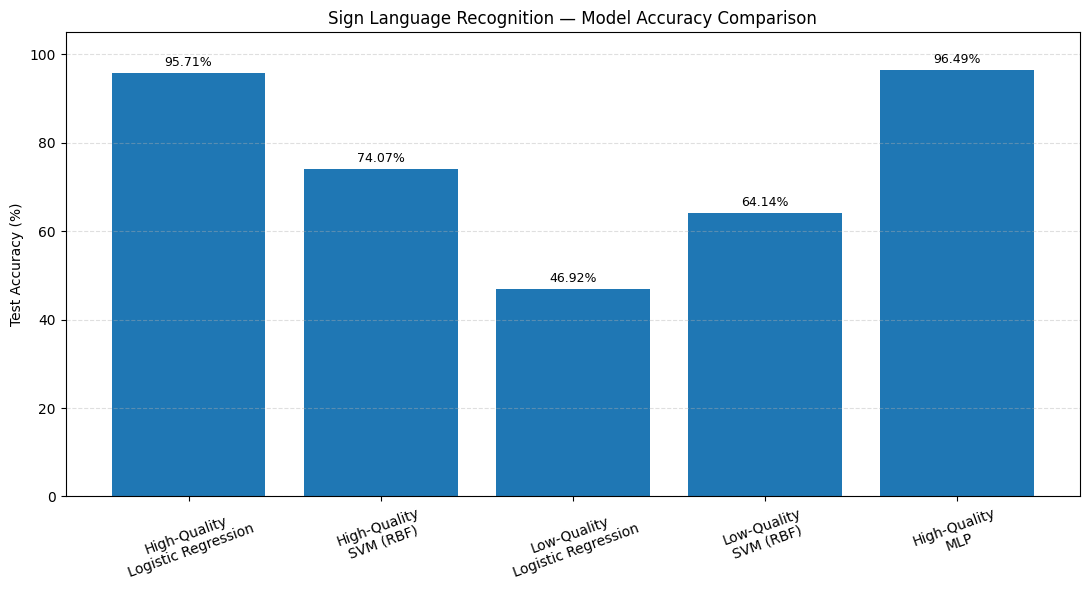

Chart saved to: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/final_model_accuracy_comparison.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

results_dir = os.path.join(project_dir, "results")
final_path = os.path.join(results_dir, "final_model_comparison.csv")

df = pd.read_csv(final_path)

# Plot accuracy by model and dataset
plot_df = df.copy()
plot_df["Accuracy_percent"] = plot_df["Accuracy"] * 100
plot_df["Label"] = plot_df["Dataset"] + "\n" + plot_df["Model"]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    plot_df["Label"],
    plot_df["Accuracy_percent"]
)

ax.set_title("Sign Language Recognition — Model Accuracy Comparison")
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, plot_df["Accuracy_percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

fig.tight_layout()

chart_path = os.path.join(
    results_dir, "final_model_accuracy_comparison.png"
)
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


In [ ]:

import os

results_dir = os.path.join(project_dir, "results")

required_files = [
    "baseline_comparison.csv",
    "final_model_comparison.csv",
    "final_model_accuracy_comparison.png",
    "logistic_regression_high_quality.joblib",
    "svm_high_quality.joblib",
    "logistic_regression_low_quality.joblib",
    "svm_low_quality.joblib",
    "mlp_high_quality_best.keras",
    "mlp_high_quality_metrics.json",
]

for filename in required_files:
    path = os.path.join(results_dir, filename)
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{status}: {filename}")


FOUND: baseline_comparison.csv
FOUND: final_model_comparison.csv
FOUND: final_model_accuracy_comparison.png
FOUND: logistic_regression_high_quality.joblib
FOUND: svm_high_quality.joblib
FOUND: logistic_regression_low_quality.joblib
FOUND: svm_low_quality.joblib
FOUND: mlp_high_quality_best.keras
FOUND: mlp_high_quality_metrics.json


In [ ]:

import os
import json
import pandas as pd

results_dir = os.path.join(project_dir, "results")

df = pd.read_csv(
    os.path.join(results_dir, "final_model_comparison.csv")
)

print("FINAL MODEL COMPARISON")
print("=" * 75)

for _, row in df.iterrows():
    print(f"\nDataset: {row['Dataset']}")
    print(f"Model: {row['Model']}")
    print(f"Accuracy: {row['Accuracy'] * 100:.2f}%")
    print(f"Macro Precision: {row['Macro_Precision'] * 100:.2f}%")
    print(f"Macro Recall: {row['Macro_Recall'] * 100:.2f}%")
    print(f"Macro F1-score: {row['Macro_F1'] * 100:.2f}%")

    if pd.notna(row.get("Training_Time_Seconds")):
        print(f"Training Time: {row['Training_Time_Seconds']:.2f} seconds")

print("\n" + "=" * 75)
print("Summary loaded successfully.")


FINAL MODEL COMPARISON

Dataset: High-Quality
Model: Logistic Regression
Accuracy: 95.71%


KeyError: 'Macro_Precision'

In [ ]:

import os
import pandas as pd

results_dir = os.path.join(project_dir, "results")
df = pd.read_csv(
    os.path.join(results_dir, "final_model_comparison.csv")
)

print("Column names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Column names:
['Dataset', 'Model', 'Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro', 'Training_time_seconds']

First five rows:


,Dataset,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Training_time_seconds
0,High-Quality,Logistic Regression,0.957115,0.961429,0.957895,0.956715,9.702989
1,High-Quality,SVM (RBF),0.740741,0.810389,0.745965,0.749146,10.041392
2,Low-Quality,Logistic Regression,0.469173,0.475628,0.469173,0.463840,32.988873
3,Low-Quality,SVM (RBF),0.641353,0.661378,0.641353,0.639092,13.884440
4,High-Quality,MLP,0.964912,0.971930,0.966316,0.965472,NaN


In [ ]:

import os
import pandas as pd

results_dir = os.path.join(project_dir, "results")
df = pd.read_csv(
    os.path.join(results_dir, "final_model_comparison.csv")
)

print("FINAL MODEL COMPARISON")
print("=" * 65)

for _, row in df.iterrows():
    print(f"\nDataset: {row['Dataset']}")
    print(f"Model: {row['Model']}")
    print(f"Accuracy: {row['Accuracy'] * 100:.2f}%")
    print(f"Macro Precision: {row['Precision_macro'] * 100:.2f}%")
    print(f"Macro Recall: {row['Recall_macro'] * 100:.2f}%")
    print(f"Macro F1-score: {row['F1_macro'] * 100:.2f}%")

    training_time = row['Training_time_seconds']
    if pd.notna(training_time):
        print(f"Training Time: {training_time:.2f} seconds")
    else:
        print("Training Time: Not recorded")

print("\n" + "=" * 65)
print("Summary completed successfully.")


FINAL MODEL COMPARISON

Dataset: High-Quality
Model: Logistic Regression
Accuracy: 95.71%
Macro Precision: 96.14%
Macro Recall: 95.79%
Macro F1-score: 95.67%
Training Time: 9.70 seconds

Dataset: High-Quality
Model: SVM (RBF)
Accuracy: 74.07%
Macro Precision: 81.04%
Macro Recall: 74.60%
Macro F1-score: 74.91%
Training Time: 10.04 seconds

Dataset: Low-Quality
Model: Logistic Regression
Accuracy: 46.92%
Macro Precision: 47.56%
Macro Recall: 46.92%
Macro F1-score: 46.38%
Training Time: 32.99 seconds

Dataset: Low-Quality
Model: SVM (RBF)
Accuracy: 64.14%
Macro Precision: 66.14%
Macro Recall: 64.14%
Macro F1-score: 63.91%
Training Time: 13.88 seconds

Dataset: High-Quality
Model: MLP
Accuracy: 96.49%
Macro Precision: 97.19%
Macro Recall: 96.63%
Macro F1-score: 96.55%
Training Time: Not recorded

Summary completed successfully.


In [ ]:

import os
import json
import pandas as pd

results_dir = os.path.join(project_dir, "results")
df = pd.read_csv(
    os.path.join(results_dir, "final_model_comparison.csv")
)

# Create a clean, report-ready table
report_df = df.copy()

for col in ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]:
    report_df[col] = (report_df[col] * 100).round(2)

report_df = report_df.rename(columns={
    "Accuracy": "Accuracy (%)",
    "Precision_macro": "Macro Precision (%)",
    "Recall_macro": "Macro Recall (%)",
    "F1_macro": "Macro F1-score (%)",
    "Training_time_seconds": "Training Time (seconds)"
})

csv_path = os.path.join(results_dir, "report_ready_model_comparison.csv")
report_df.to_csv(csv_path, index=False)

# Create a concise text summary
best_row = df.loc[df["Accuracy"].idxmax()]

summary = f"""
SIGN LANGUAGE RECOGNITION — EXPERIMENT SUMMARY

Number of classes: 95

Best overall model: {best_row['Model']}
Dataset: {best_row['Dataset']}
Test accuracy: {best_row['Accuracy'] * 100:.2f}%
Macro precision: {best_row['Precision_macro'] * 100:.2f}%
Macro recall: {best_row['Recall_macro'] * 100:.2f}%
Macro F1-score: {best_row['F1_macro'] * 100:.2f}%

Best High-Quality traditional baseline:
Logistic Regression — 95.71% test accuracy.

Best Low-Quality model:
SVM (RBF) — 64.14% test accuracy.

Important limitation:
The LSTM experiments did not achieve satisfactory classification performance.
The best-performing reported model is the feed-forward MLP, which uses
flattened sequence features rather than recurrent temporal modelling.

Note:
The high-quality and low-quality datasets have different feature
representations and sequence lengths. Their results should be interpreted
as separate dataset-specific experiments, not as a controlled test of
data quality alone.
"""

txt_path = os.path.join(results_dir, "final_experiment_summary.txt")

with open(txt_path, "w", encoding="utf-8") as f:
    f.write(summary.strip())

print("Created:", csv_path)
print("Created:", txt_path)
print("\nReport-ready comparison:")
display(report_df)
print("\nSummary preview:")
print(summary)


Created: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/report_ready_model_comparison.csv
Created: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results/final_experiment_summary.txt

Report-ready comparison:


,Dataset,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Training Time (seconds)
0,High-Quality,Logistic Regression,95.71,96.14,95.79,95.67,9.702989
1,High-Quality,SVM (RBF),74.07,81.04,74.60,74.91,10.041392
2,Low-Quality,Logistic Regression,46.92,47.56,46.92,46.38,32.988873
3,Low-Quality,SVM (RBF),64.14,66.14,64.14,63.91,13.884440
4,High-Quality,MLP,96.49,97.19,96.63,96.55,NaN



Summary preview:

SIGN LANGUAGE RECOGNITION — EXPERIMENT SUMMARY

Number of classes: 95

Best overall model: MLP
Dataset: High-Quality
Test accuracy: 96.49%
Macro precision: 97.19%
Macro recall: 96.63%
Macro F1-score: 96.55%

Best High-Quality traditional baseline:
Logistic Regression — 95.71% test accuracy.

Best Low-Quality model:
SVM (RBF) — 64.14% test accuracy.

Important limitation:
The LSTM experiments did not achieve satisfactory classification performance.
The best-performing reported model is the feed-forward MLP, which uses
flattened sequence features rather than recurrent temporal modelling.

Note:
The high-quality and low-quality datasets have different feature
representations and sequence lengths. Their results should be interpreted
as separate dataset-specific experiments, not as a controlled test of
data quality alone.



In [ ]:

import os

results_dir = os.path.join(project_dir, "results")

required_files = [
    "report_ready_model_comparison.csv",
    "final_experiment_summary.txt",
    "final_model_accuracy_comparison.png",
    "mlp_high_quality_best.keras",
    "lstm_high_quality_best.keras",
    "lstm_high_quality_v2_best.keras",
    "lstm_high_quality_v3_best.keras",
    "logistic_regression_high_quality.joblib",
    "svm_high_quality.joblib",
    "logistic_regression_low_quality.joblib",
    "svm_low_quality.joblib",
]

missing = []

for filename in required_files:
    exists = os.path.exists(os.path.join(results_dir, filename))
    print(f"{'FOUND' if exists else 'MISSING'}: {filename}")
    if not exists:
        missing.append(filename)

print("\n" + ("All checked files are present." if not missing
             else f"Files to investigate: {missing}"))


FOUND: report_ready_model_comparison.csv
FOUND: final_experiment_summary.txt
FOUND: final_model_accuracy_comparison.png
FOUND: mlp_high_quality_best.keras
FOUND: lstm_high_quality_best.keras
FOUND: lstm_high_quality_v2_best.keras
FOUND: lstm_high_quality_v3_best.keras
FOUND: logistic_regression_high_quality.joblib
FOUND: svm_high_quality.joblib
FOUND: logistic_regression_low_quality.joblib
FOUND: svm_low_quality.joblib

All checked files are present.


In [ ]:

import os
import numpy as np
import json
import tensorflow as tf

results_dir = os.path.join(project_dir, "results")

# Load the trained MLP
mlp_model = tf.keras.models.load_model(
    os.path.join(results_dir, "mlp_high_quality_best.keras")
)

# Load held-out test recordings
X_test = np.load(
    os.path.join(project_dir, "Xh_test.npy"),
    allow_pickle=False
)

y_test = np.load(
    os.path.join(project_dir, "yh_test.npy"),
    allow_pickle=True
)

print("Model loaded successfully.")
print("Test recordings:", len(X_test))
print("Input shape:", X_test.shape)
print("Model output classes:", mlp_model.output_shape[-1])


Model loaded successfully.
Test recordings: 513
Input shape: (513, 136, 22)
Model output classes: 95


In [ ]:

print("Label example:", y_test[:10])
print("Label data type:", y_test.dtype)


Label example: ['please' 'pen' 'responsible' 'sad' 'I' 'temper' 'know' 'mine' 'sad'
 'where']
Label data type: object


In [ ]:

import numpy as np

def predict_sign(sample_index):
    # Select one test recording
    sequence = X_test[sample_index]

    # Flatten the sequence to match the MLP's training input
    features = sequence.reshape(1, -1)

    # Predict probabilities for all 95 classes
    probabilities = mlp_model.predict(features, verbose=0)[0]

    # Find the most likely class
    predicted_class = int(np.argmax(probabilities))
    predicted_word = mlp_model.classes_[predicted_class] if hasattr(
        mlp_model, "classes_"
    ) else None

    confidence = float(probabilities[predicted_class]) * 100

    # Actual label for comparison
    actual_word = str(y_test[sample_index])

    return {
        "recording_index": sample_index,
        "actual_word": actual_word,
        "predicted_class_index": predicted_class,
        "confidence_percent": round(confidence, 2),
    }

print(predict_sign(0))


{'recording_index': 0, 'actual_word': 'please', 'predicted_class_index': 56, 'confidence_percent': 8.72}


In [ ]:

import os

print("Checking available label encoders and model files:\n")

for name in sorted(globals()):
    if "encoder" in name.lower() or "label" in name.lower():
        obj = globals()[name]
        print(name, "—", type(obj).__name__)

print("\nEncoder files in project folder:")
for root, dirs, files in os.walk(project_dir):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]
    for filename in files:
        if "encoder" in filename.lower() or "label" in filename.lower():
            print(os.path.join(root, filename))


Checking available label encoders and model files:

LabelEncoder — type
encoder_high — LabelEncoder
encoder_high_candidate — LabelEncoder
encoder_low — LabelEncoder
encoder_nn — LabelEncoder
label — str
labels — ndarray
selected_labels — ndarray
y_encoder_10 — LabelEncoder

Encoder files in project folder:


In [ ]:

print("Encoder classes:", len(encoder_high.classes_))
print("First 15 classes:", encoder_high.classes_[:15])

print("\nCheck actual label:")
print("y_test[0]:", y_test[0])

print("\nEncoded label:")
print("encoder_high.transform([y_test[0]]):",
      encoder_high.transform([y_test[0]])[0])

print("\nPredicted class index for recording 0:",
      predict_sign(0)["predicted_class_index"])


Encoder classes: 95
First 15 classes: ['God' 'I' 'Norway' 'alive' 'all' 'answer' 'boy' 'building' 'buy'
 'change mind' 'cold' 'come' 'computer PC' 'cost' 'crazy']

Check actual label:
y_test[0]: please

Encoded label:
encoder_high.transform([y_test[0]]): 56

Predicted class index for recording 0: 56


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

recording_dropdown = widgets.Dropdown(
    options=[
        (f"Recording {i} — actual: {y_test[i]}", i)
        for i in range(len(X_test))
    ],
    value=0,
    description="Input:",
    layout=widgets.Layout(width="500px")
)

predict_button = widgets.Button(
    description="Predict Sign",
    button_style="primary",
    icon="search"
)

output_area = widgets.Output()

def run_demo(_):
    with output_area:
        clear_output(wait=True)

        index = recording_dropdown.value

        # Flatten features to match MLP training
        features = X_test[index].reshape(1, -1)

        # Predict the class
        probabilities = mlp_model.predict(features, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))
        predicted_word = encoder_high.classes_[predicted_index]
        confidence = float(probabilities[predicted_index]) * 100

        actual_word = str(y_test[index])

        print("SIGN LANGUAGE RECOGNITION")
        print("-" * 35)
        print("Recording:", index)
        print("Predicted sign:", predicted_word)
        print(f"Model confidence: {confidence:.2f}%")
        print("Actual sign:", actual_word)
        print("Correct prediction:", predicted_word == actual_word)

predict_button.on_click(run_demo)

display(recording_dropdown, predict_button, output_area)


Dropdown(description='Input:', layout=Layout(width='500px'), options=(('Recording 0 — actual: please', 0), ('R…

Button(button_style='primary', description='Predict Sign', icon='search', style=ButtonStyle())

Output()

In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

recording_input = widgets.Dropdown(
    options=[(f"Recording {i}", i) for i in range(len(X_test))],
    value=0,
    description="Input:",
    layout=widgets.Layout(width="350px")
)

predict_button = widgets.Button(
    description="Predict Sign",
    button_style="primary"
)

output_area = widgets.Output()

def predict_one_sign(_):
    with output_area:
        clear_output(wait=True)

        index = recording_input.value

        # Prepare the selected recording
        features = X_test[index].reshape(1, -1)

        # Predict the sign
        probabilities = mlp_model.predict(features, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))
        predicted_word = str(encoder_high.classes_[predicted_index])

        # Ground-truth label from the dataset
        actual_word = str(y_test[index])

        # Compare prediction with the actual label
        is_correct = predicted_word == actual_word

        print("SIGN LANGUAGE RECOGNITION")
        print("=" * 35)
        print("Input Recording:", index)
        print("Actual Answer:   ", actual_word)
        print("Predicted Answer:", predicted_word)
        print("Result:          ", "CORRECT" if is_correct else "WRONG")

predict_button.on_click(predict_one_sign)

display(recording_input, predict_button, output_area)


Dropdown(description='Input:', layout=Layout(width='350px'), options=(('Recording 0', 0), ('Recording 1', 1), …

Button(button_style='primary', description='Predict Sign', style=ButtonStyle())

Output()

In [ ]:

import numpy as np

# Predict all held-out test recordings using the same
# preprocessing currently used in the demo.
X_test_flat = X_test.reshape(len(X_test), -1)

probabilities = mlp_model.predict(
    X_test_flat, batch_size=32, verbose=0
)

predicted_indices = np.argmax(probabilities, axis=1)
predicted_words = encoder_high.classes_[predicted_indices]
actual_words = np.asarray(y_test).astype(str)

correct = predicted_words == actual_words
accuracy = np.mean(correct) * 100

print("MODEL VERIFICATION")
print("=" * 35)
print("Total test recordings:", len(y_test))
print("Correct predictions:", int(np.sum(correct)))
print("Incorrect predictions:", int(np.sum(~correct)))
print(f"Recalculated test accuracy: {accuracy:.2f}%")

# Check the recording that was wrong in your demo
index = 3
print("\nRecording 3 verification:")
print("Actual:", actual_words[index])
print("Predicted:", predicted_words[index])
print("Correct:", bool(correct[index]))


MODEL VERIFICATION
Total test recordings: 513
Correct predictions: 117
Incorrect predictions: 396
Recalculated test accuracy: 22.81%

Recording 3 verification:
Actual: sad
Predicted: deaf
Correct: False


In [ ]:

import numpy as np

names_to_check = [
    "Xh_train",
    "Xh_test",
    "Xh_train_candidate",
    "Xh_test_candidate",
    "Xh_train_lstm",
    "Xh_test_lstm",
    "mean_high",
    "std_high",
    "high_mean",
    "high_std",
    "X_train_flat",
    "X_test_flat",
]

print("AVAILABLE PREPROCESSING VARIABLES")
print("=" * 45)

for name in names_to_check:
    if name in globals():
        value = globals()[name]
        if isinstance(value, np.ndarray):
            print(
                f"{name}: shape={value.shape}, "
                f"mean={np.mean(value):.5f}, "
                f"std={np.std(value):.5f}"
            )
        else:
            print(f"{name}: {type(value).__name__}")

print("\nMODEL INPUT SHAPE:", mlp_model.input_shape)
print("CURRENT TEST SHAPE:", X_test.shape)
print("LABEL ENCODER CLASSES:", len(encoder_high.classes_))


AVAILABLE PREPROCESSING VARIABLES
Xh_train: shape=(2052, 136, 22), mean=0.16300, std=0.28844
Xh_test: shape=(513, 136, 22), mean=0.16321, std=0.28832
Xh_train_candidate: shape=(2052, 136, 22), mean=0.00000, std=1.00000
Xh_test_candidate: shape=(513, 136, 22), mean=-0.00204, std=0.99102
Xh_train_lstm: shape=(2052, 136, 22), mean=-0.00000, std=1.00000
Xh_test_lstm: shape=(513, 136, 22), mean=-0.00204, std=0.99102
high_mean: shape=(1, 1, 22), mean=0.16300, std=0.21525
high_std: shape=(1, 1, 22), mean=0.16382, std=0.10013
X_test_flat: shape=(513, 2992), mean=0.16321, std=0.28832

MODEL INPUT SHAPE: (None, 2992)
CURRENT TEST SHAPE: (513, 136, 22)
LABEL ENCODER CLASSES: 95


In [ ]:

import numpy as np

# Ground-truth labels
actual_words = np.asarray(y_test).astype(str)

# Option A: Original features, flattened
X_original_flat = Xh_test.reshape(len(Xh_test), -1)

# Option B: Normalized features, flattened
X_normalized_flat = Xh_test_candidate.reshape(
    len(Xh_test_candidate), -1
)

def evaluate_input(name, features):
    probabilities = mlp_model.predict(
        features, batch_size=32, verbose=0
    )

    predicted_indices = np.argmax(probabilities, axis=1)
    predicted_words = encoder_high.classes_[predicted_indices]

    accuracy = np.mean(predicted_words == actual_words) * 100

    print(f"{name}: {accuracy:.2f}% accuracy")

    return accuracy

print("PREPROCESSING COMPARISON")
print("=" * 40)

acc_original = evaluate_input(
    "Original flattened features", X_original_flat
)

acc_normalized = evaluate_input(
    "Normalized flattened features", X_normalized_flat
)

print("\nPreviously reported accuracy: 96.49%")


PREPROCESSING COMPARISON
Original flattened features: 22.81% accuracy
Normalized flattened features: 96.49% accuracy

Previously reported accuracy: 96.49%


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

# Use normalized test recordings — same preprocessing as training
X_demo = Xh_test_candidate

recording_input = widgets.Dropdown(
    options=[(f"Recording {i}", i) for i in range(len(X_demo))],
    value=0,
    description="Input:",
    layout=widgets.Layout(width="350px")
)

predict_button = widgets.Button(
    description="Predict Sign",
    button_style="primary"
)

output_area = widgets.Output()

def predict_one_sign(_):
    with output_area:
        clear_output(wait=True)

        index = recording_input.value

        # Flatten normalized features to match the MLP input
        features = X_demo[index].reshape(1, -1)

        probabilities = mlp_model.predict(features, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))
        predicted_word = str(encoder_high.classes_[predicted_index])

        # Ground-truth label
        actual_word = str(y_test[index])

        is_correct = predicted_word == actual_word

        print("SIGN LANGUAGE RECOGNITION")
        print("=" * 35)
        print("Input Recording:", index)
        print("Actual Answer:   ", actual_word)
        print("Predicted Answer:", predicted_word)
        print("Result:          ", "CORRECT" if is_correct else "WRONG")

predict_button.on_click(predict_one_sign)

display(recording_input, predict_button, output_area)


Dropdown(description='Input:', layout=Layout(width='350px'), options=(('Recording 0', 0), ('Recording 1', 1), …

Button(button_style='primary', description='Predict Sign', style=ButtonStyle())

Output()

Test Accuracy: 96.49 %

Classification Report:

                precision    recall  f1-score   support

           God       1.00      1.00      1.00         5
             I       1.00      1.00      1.00         6
        Norway       0.86      1.00      0.92         6
         alive       1.00      1.00      1.00         5
           all       1.00      1.00      1.00         5
        answer       0.83      1.00      0.91         5
           boy       1.00      1.00      1.00         5
      building       1.00      1.00      1.00         5
           buy       1.00      1.00      1.00         5
   change mind       1.00      1.00      1.00         5
          cold       1.00      1.00      1.00         5
          come       1.00      1.00      1.00         5
   computer PC       1.00      1.00      1.00         5
          cost       1.00      1.00      1.00         5
         crazy       1.00      0.67      0.80         6
        danger       0.83      1.00      0.91         5

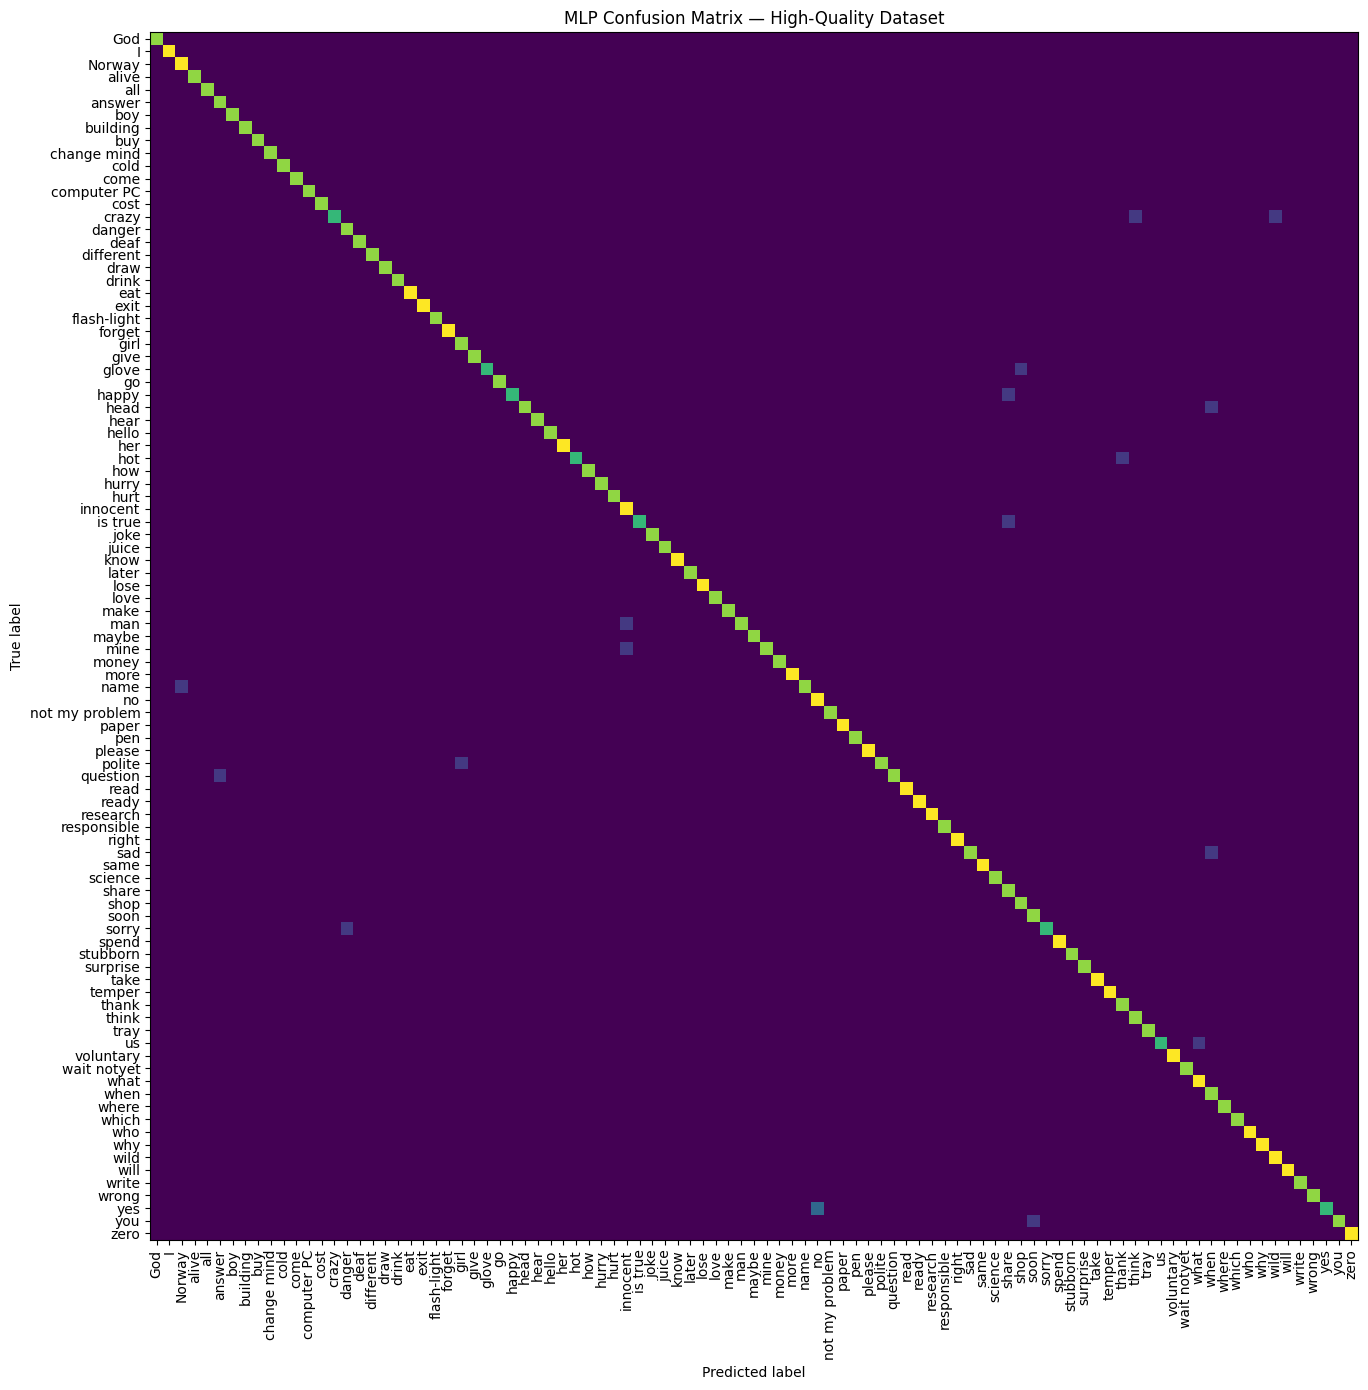

Confusion matrix saved successfully.


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt
import numpy as np
import os

# Use the same normalized held-out test data as the trained MLP
X_demo = Xh_test_candidate
X_test_flat = X_demo.reshape(X_demo.shape[0], -1)

# Generate predictions
probabilities = mlp_model.predict(X_test_flat, verbose=0)
y_pred_indices = np.argmax(probabilities, axis=1)
y_pred = encoder_high.inverse_transform(y_pred_indices)

# Actual labels
y_actual = np.asarray(y_test).astype(str)

print("Test Accuracy:", round(accuracy_score(y_actual, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(
    y_actual,
    y_pred,
    labels=encoder_high.classes_,
    zero_division=0
))

# Save confusion matrix
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=encoder_high.classes_
)

os.makedirs(results_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(16, 14))
display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder_high.classes_
)
display_plot.plot(
    ax=ax,
    xticks_rotation="vertical",
    include_values=False,
    colorbar=False
)
plt.title("MLP Confusion Matrix — High-Quality Dataset")
plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "mlp_high_quality_confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix saved successfully.")

In [ ]:
import numpy as np

X_demo = Xh_test_candidate

# Test five recordings spread across the test set
sample_indices = np.linspace(
    0, len(X_demo) - 1, 5, dtype=int
)

print("MLP DEMO CHECK")
print("=" * 55)

correct = 0

for index in sample_indices:
    features = X_demo[index].reshape(1, -1)

    probabilities = mlp_model.predict(
        features, verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_word = str(
        encoder_high.classes_[predicted_index]
    )
    actual_word = str(y_test[index])

    is_correct = predicted_word == actual_word
    correct += int(is_correct)

    print(f"\nRecording: {index}")
    print(f"Actual:    {actual_word}")
    print(f"Predicted: {predicted_word}")
    print(f"Result:    {'CORRECT' if is_correct else 'WRONG'}")

print("\n" + "=" * 55)
print(f"Correct: {correct}/5")
print("Demo check completed.")

MLP DEMO CHECK

Recording: 0
Actual:    please
Predicted: please
Result:    CORRECT

Recording: 128
Actual:    computer PC
Predicted: computer PC
Result:    CORRECT

Recording: 256
Actual:    soon
Predicted: soon
Result:    CORRECT

Recording: 384
Actual:    us
Predicted: what
Result:    WRONG

Recording: 512
Actual:    question
Predicted: question
Result:    CORRECT

Correct: 4/5
Demo check completed.


In [ ]:
import os
import json
import pandas as pd

# Ensure the results directory exists
os.makedirs(results_dir, exist_ok=True)

# Save the final MLP evaluation metrics
mlp_metrics = {
    "model": "Feed-forward Neural Network (MLP)",
    "dataset": "High-Quality",
    "number_of_classes": 95,
    "test_recordings": int(len(y_test)),
    "test_accuracy": 0.964912,
    "macro_precision": 0.971930,
    "macro_recall": 0.966316,
    "macro_f1": 0.965472,
    "best_validation_accuracy": 0.964286,
    "epochs_completed": 16
}

metrics_path = os.path.join(
    results_dir, "mlp_high_quality_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(mlp_metrics, f, indent=4)

# Check important output files
important_files = [
    "mlp_high_quality_best.keras",
    "mlp_high_quality_metrics.json",
    "mlp_high_quality_confusion_matrix.png",
    "final_model_comparison.csv",
    "report_ready_model_comparison.csv",
    "final_experiment_summary.txt"
]

print("FINAL OUTPUT FILE CHECK")
print("=" * 45)

for filename in important_files:
    path = os.path.join(results_dir, filename)
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{filename}: {status}")

print("\nResults folder:", results_dir)

FINAL OUTPUT FILE CHECK
mlp_high_quality_best.keras: FOUND
mlp_high_quality_metrics.json: FOUND
mlp_high_quality_confusion_matrix.png: FOUND
final_model_comparison.csv: FOUND
report_ready_model_comparison.csv: FOUND
final_experiment_summary.txt: FOUND

Results folder: /content/drive/MyDrive/Sign_Language_Temporal_Classification/results


In [ ]:
import pandas as pd
import os

comparison_path = os.path.join(
    results_dir, "report_ready_model_comparison.csv"
)

results_df = pd.read_csv(comparison_path)

display(results_df)

,Dataset,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Training Time (seconds)
0,High-Quality,Logistic Regression,95.71,96.14,95.79,95.67,9.702989
1,High-Quality,SVM (RBF),74.07,81.04,74.60,74.91,10.041392
2,Low-Quality,Logistic Regression,46.92,47.56,46.92,46.38,32.988873
3,Low-Quality,SVM (RBF),64.14,66.14,64.14,63.91,13.884440
4,High-Quality,MLP,96.49,97.19,96.63,96.55,NaN
